# TimeGAN results and reference review

AMZN Level 10, 21 June 2012. The starting-book conditioning study comes first, followed by the earlier repeated-seed comparisons and full experiment record. All scores use validation data; the final test remains unscored. Execution reads saved reports and figures without training.

In [1]:
from pathlib import Path
import hashlib, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

parents = [Path.cwd(), *Path.cwd().parents]
relative = Path("recognition/timegan_spagheddy7")
locations = [*parents, *[p / relative for p in parents], *[p / "Project/2.7/PatternAnalysis-2026" / relative for p in parents]]
project = next(p for p in locations if (p / "reports/timegan/results.json").is_file())
report = json.loads((project / "reports/timegan/results.json").read_text(encoding="utf-8"))
source_changes = [name for name, expected in report["source_files"].items()
                  if hashlib.sha256((project / name).read_text(encoding="utf-8").encode()).hexdigest() != expected]
print("Reference run predates these source changes:", source_changes or "none")
print("Historical sources are archived. The reviewed default trainer reproduces the preceding trainer updates exactly.")
assert report["comparison_signature"] == json.loads((project / "reports/ar/results.json").read_text())["comparison_signature"]
selected, config = report["selected"], report["config"]
history, validation = pd.DataFrame(report["history"]), pd.DataFrame(report["validation_history"])
def mean_sd(row, metric, scale=1):
    return f"{row[metric + '_mean'] * scale:.4f} ± {row[metric + '_sd'] * scale:.4f}"
for item in report["figures"].values():
    assert hashlib.sha256((project / "reports/timegan" / item["file"]).read_bytes()).hexdigest() == item["sha256"]
def figure(name):
    display(Image(filename=str(project / "reports/timegan" / report["figures"][name]["file"]), width=1050))

tuning = json.loads((project / "reports/timegan/tuning.json").read_text())
metrics = [("invalid_rate", "Invalid (%)", 100), ("kl_spread", "Spread KL", 1), ("kl_mid_return", "Return KL", 1),
           ("abs_return_acf_mae", "ACF error", 1), ("depth_ssim", "Depth SSIM", 1)]
scales, labels = {k: s for k, _, s in metrics}, {k: label for k, label, _ in metrics}


Reference run predates these source changes: ['modules.py', 'train.py', 'predict.py', 'protocol.py']
Historical sources are archived. The reviewed default trainer reproduces the preceding trainer updates exactly.


## Starting-book conditioning

Test whether known starting price gaps help the model generate compatible log-return paths. The 19 inputs are the best spread, nine ask gaps and nine bid gaps, expressed as log relative gaps and standardised using training-window anchors only. No future prices or held-out volumes enter the model.

All five networks receive the same static context. The matched model gets its own anchor; the control gets 19 zeros. Both have 61,361 parameters, identical initial weights and paired minibatch/noise streams. Both retain temporal supervision, order weight 0.001 and 5,000 updates per stage. This isolates context information from added input dimensions.

This is an extension to the [released code](https://github.com/jsyoon0823/TimeGAN/blob/8f6181cb9b9d2fa0c930cd902411d9ac8a308e07/timegan.py). The [paper](https://proceedings.neurips.cc/paper_files/paper/2019/file/c9efe5f26cd17ba6216bbe2a7d26d490-Paper.pdf) also discusses static features, but jointly generates them; here the initial book is supplied.

The VARX(2) baseline uses the same context, fixed ridge 0.01 and a zero-context control. Training pairs come from complete windows with context fixed at each window's start. Historical AR/TimeGAN scores have a different input budget and are reported separately.

The selected checkpoints trade validity against fidelity: spread KL worsens from 0.166 to 0.206 and absolute-return ACF error from 0.176 to 0.306. At the fixed final step of 5,000, matched/zero invalidity is 45.56%/51.91%, but return KL is 0.882/0.462. The selected-checkpoint return improvement therefore does not persist at the final step. Neither model meets the combined task targets.

In [2]:
bundle = tuning["conditioning_report"]
bundle_path = project / "reports/timegan" / bundle["file"]
assert hashlib.sha256(bundle_path.read_text(encoding="utf-8").encode()).hexdigest() == bundle["sha256"]
conditioning = json.loads(bundle_path.read_text(encoding="utf-8"))
print(conditioning["scope"])
rows = [[r["label"], *[mean_sd(r["score"], key, scale) for key, _, scale in metrics]] for r in conditioning["comparison"]]
display(pd.DataFrame(rows, columns=["Model", *labels.values()]).set_index("Model"))
print("SD above measures three generation seeds for one fit, not retraining uncertainty.")
print(conditioning["conclusion"])
print("Predeclared pilot screen:", conditioning["plan"]["decision"])
display(pd.DataFrame(conditioning["pilot_screen"]).set_index("Criterion"))
print("Sensitivity at the fixed final joint step, without checkpoint selection:")
rows = [[r["label"], *[mean_sd(r["score"], key, scale) for key, _, scale in metrics]] for r in conditioning["final_comparison"]]
display(pd.DataFrame(rows, columns=["Model", *labels.values()]).set_index("Model"))


Pilot: one training seed (2026) per TimeGAN mode, with three generation seeds. No retraining SD or final-test result.


,Invalid (%),Spread KL,Return KL,ACF error,Depth SSIM
Model,,,,,
TimeGAN: zero context,50.9954 ± 2.0634,0.1657 ± 0.0144,0.6468 ± 0.0050,0.1760 ± 0.0012,0.1284 ± 0.0043
TimeGAN: matched context,41.6618 ± 0.4158,0.2056 ± 0.0022,0.6071 ± 0.0068,0.3063 ± 0.0151,0.1450 ± 0.0022
VARX(2): zero context,92.9707 ± 0.2072,0.1624 ± 0.0139,0.5267 ± 0.0037,0.0305 ± 0.0007,0.1492 ± 0.0018
VARX(2): matched context,92.1393 ± 0.2691,0.1527 ± 0.0072,0.5640 ± 0.0016,0.0305 ± 0.0005,0.1569 ± 0.0017


SD above measures three generation seeds for one fit, not retraining uncertainty.
Matched context gives 41.66% invalid snapshots versus 51.00% for the same-size zero-context control (gain 9.33 percentage points). Return KL is 0.607 versus 0.647; ACF error 0.306 versus 0.176; depth SSIM 0.145 versus 0.128. This is a single training-seed pilot, not confirmation across retraining seeds.
Predeclared pilot screen: Pilot only. Consider independent paired seed repeats if matched context reduces invalidity by at least 5 percentage points while return/spread KL and ACF error increase no more than 5%, depth SSIM falls no more than 0.01, and noise diversity remains. Screen all criteria together, including fixed-final checkpoints; do not claim significance or select a lucky seed.


,Passed,Value
Criterion,,
Invalidity gain at least 5 percentage points,True,9.333526
kl_spread increase at most 5%,False,0.039826
kl_mid_return increase at most 5%,True,-0.039716
abs_return_acf_mae increase at most 5%,False,0.130272
Depth SSIM drop at most 0.01,True,0.016529
Fixed-context noise SD ratios at least 0.1 in every case,True,0.123631


Sensitivity at the fixed final joint step, without checkpoint selection:


,Invalid (%),Spread KL,Return KL,ACF error,Depth SSIM
Model,,,,,
TimeGAN: zero context,51.9068 ± 1.4884,0.1459 ± 0.0056,0.4616 ± 0.0179,0.4550 ± 0.0085,0.1156 ± 0.0033
TimeGAN: matched context,45.5594 ± 0.2987,0.2510 ± 0.0049,0.8821 ± 0.0028,0.3826 ± 0.0098,0.1531 ± 0.0008


### Reconstruction and noise checks

Reconstruction uses observed features and is diagnostic, not a generation score. MSE/variance near one indicates weak reconstruction relative to a constant-mean description. Noise variation is measured at fixed update positions across 128 sequences while holding each starting context fixed; three contexts and three noise seeds are checked. Its SD ratio uses the full real validation feature SD as a descriptive scale, not a matched conditional target. Nonzero noise response alone does not establish realistic variation.

The shifted-context control keeps the same noise and decoder anchors but shifts only the model's context across windows. This diagnoses reliance on the supplied context; it is not a competing simulator or a model-selection score.

Noise response survives in all three fixed contexts, but is reduced: matched price SD ratios are 0.124-0.376 and volume ratios 0.281-0.444, relative to full validation feature SD. These are descriptive scales, not proof of realistic conditional diversity. Shifting only the supplied context changes the generated features, yet invalidity stays similar (41.35% shifted versus 41.66% correct). This pilot does not demonstrate a validity benefit specific to the correctly matched starting book.

Even reconstruction of observed validation features produces 19.38% invalid snapshots with matched context; price MSE/variance is 1.044 and volume MSE/variance 0.376. Generated volumes change at every transition in the three fixed cases. The next targeted check is whether reconstruction preserves price ladders and sparse volume updates on training data, then whether joint training degrades that reconstruction. Use those diagnostics to choose one controlled change before further candidate training; additional seeds of this failed screen are not the immediate priority.

MSE / variance  \
Model                    Split      Feature group                   
TimeGAN: zero context    train      price                 0.88445   
                                    volume                0.24848   
                         validation price                 1.16309   
                                    volume                0.27096   
TimeGAN: matched context train      price                 0.87999   
                                    volume                0.34291   
                         validation price                 1.04404   
                                    volume                0.37579   

                                                   Reconstructed invalid (%)  
Model                    Split      Feature group                             
TimeGAN: zero context    train      price                           20.37354  
                                    volume                          20.37354  
                         validation price                           29.73669  
                                    volume                          29.73669  
TimeGAN: matched context train      price                           17.71240  
                                    volume                          17.71240  
                         validation price                           19.37500  
                                    volume                          19.37500

Price noise SD  Volume noise SD  \
Model                    Validation window                                    
TimeGAN: zero context    1                        0.006631         0.116849   
                         540                      0.006631         0.116849   
                         1080                     0.006631         0.116849   
TimeGAN: matched context 1                        0.000560         0.038211   
                         540                      0.001704         0.060413   
                         1080                     0.001015         0.040725   

                                            Price SD / real  Volume SD / real  
Model                    Validation window                                     
TimeGAN: zero context    1                         1.464335          0.859474  
                         540                       1.464335          0.859474  
                         1080                      1.464335          0.859474  
TimeGAN: matched context 1                         0.123631          0.281056  
                         540                       0.376210          0.444359  
                         1080                      0.224092          0.299546

,Correct context invalid (%),Shifted context invalid (%),Max feature difference
Model,,,
TimeGAN: zero context,50.99537,50.99537,0.0000
TimeGAN: matched context,41.66184,41.34742,0.7726


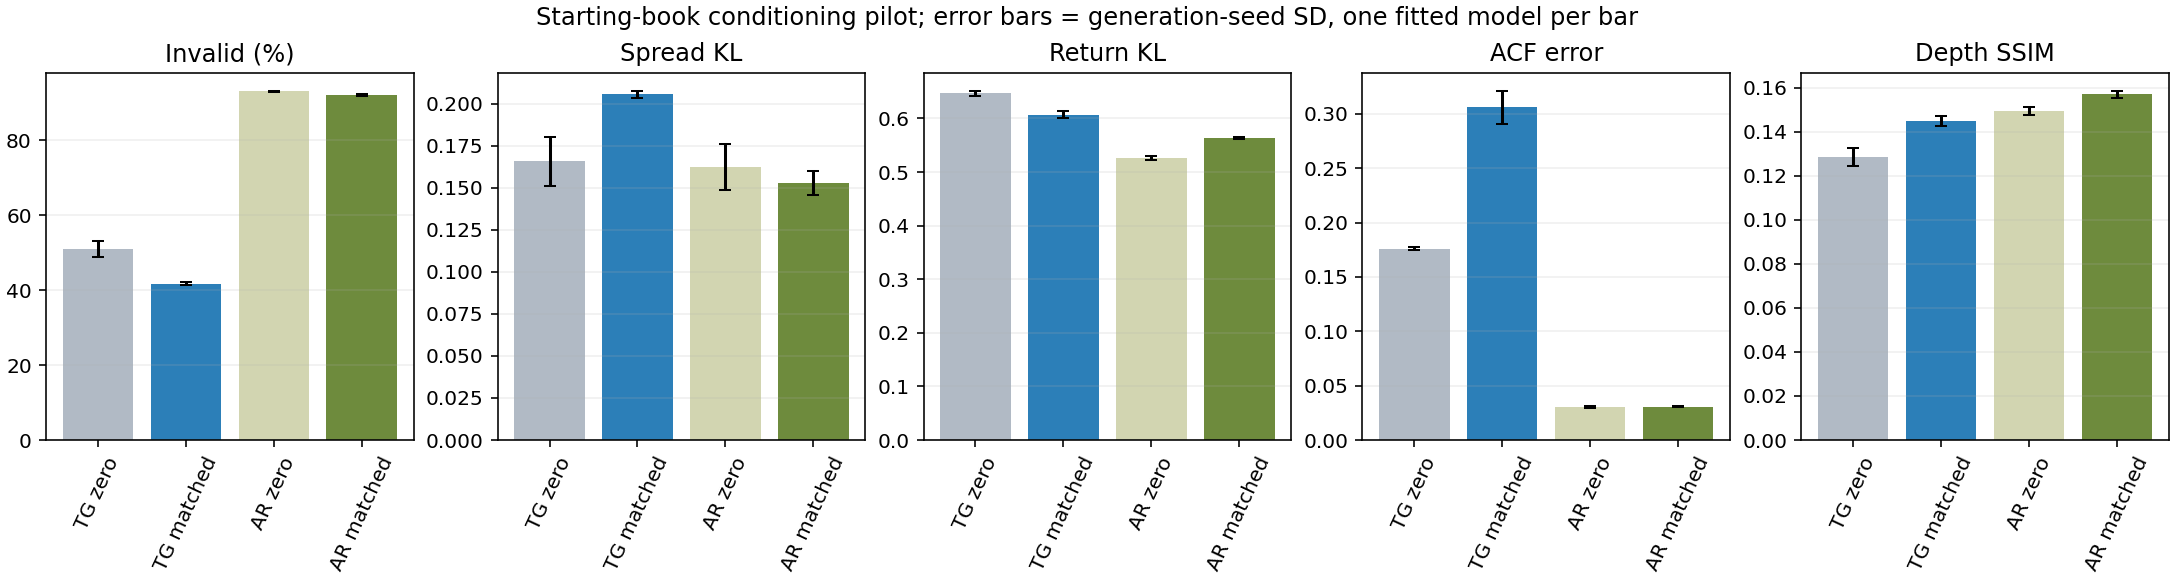

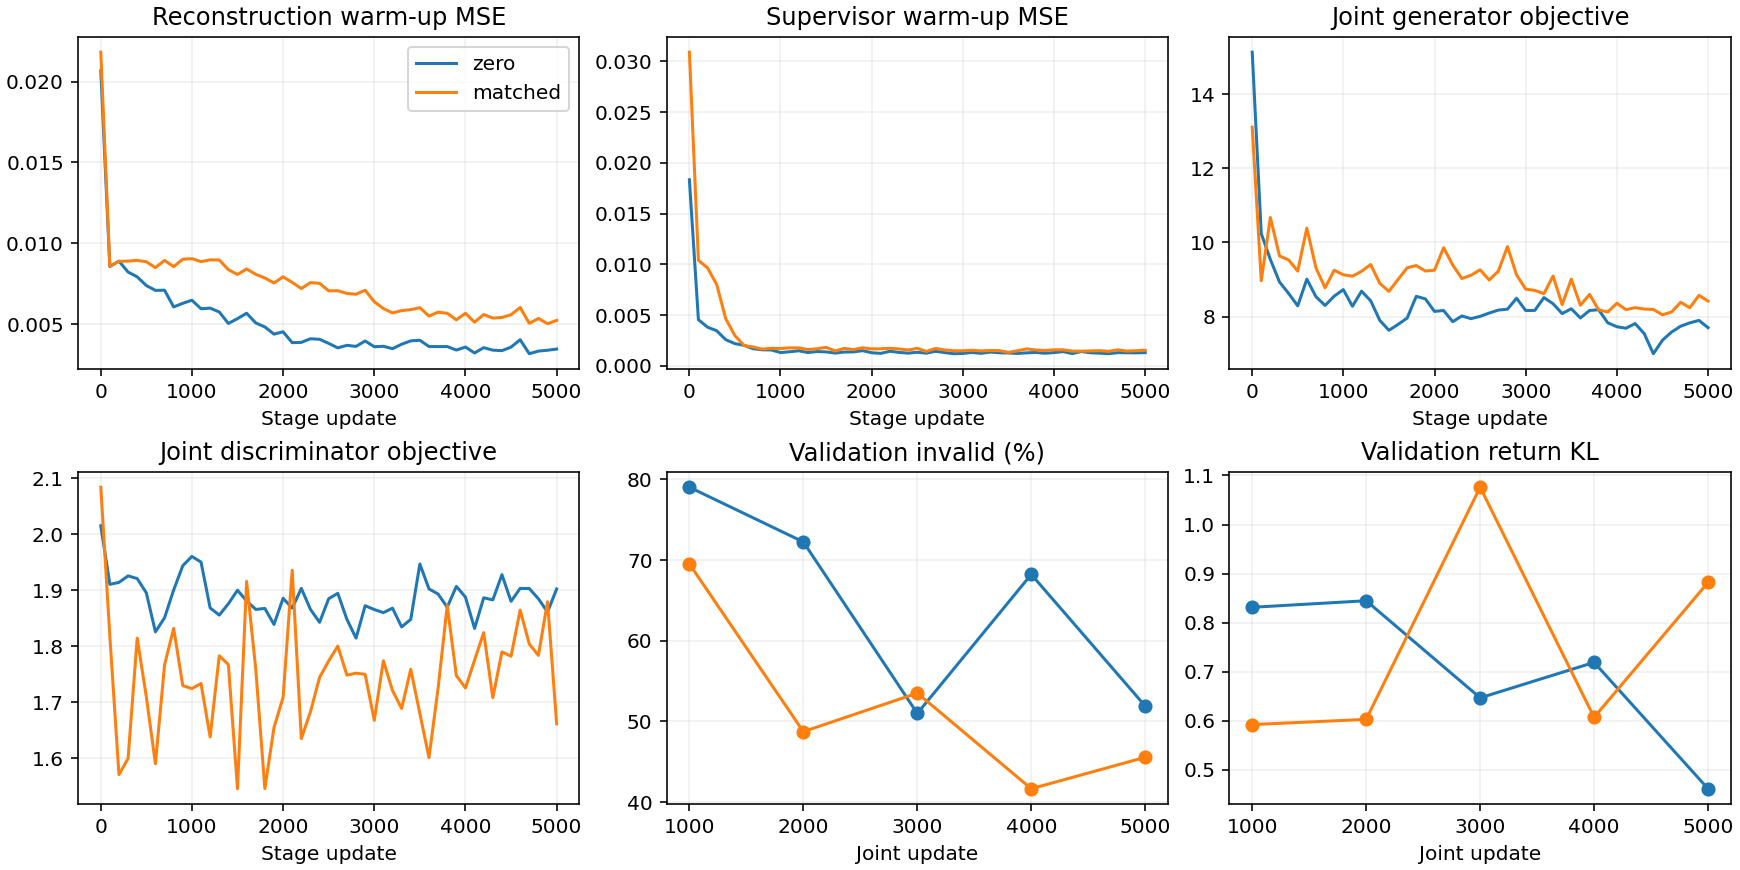

In [3]:
display(pd.DataFrame(conditioning["reconstruction_rows"]).set_index(["Model", "Split", "Feature group"]).round(5))
display(pd.DataFrame(conditioning["noise_rows"]).set_index(["Model", "Validation window"]).round(6))
display(pd.DataFrame(conditioning["shifted_context_rows"]).set_index("Model").round(5))
def conditioning_figure(key):
    item = conditioning["figures"][key]
    path = project / "reports/timegan" / item["file"]
    assert hashlib.sha256(path.read_bytes()).hexdigest() == item["sha256"]
    display(Image(filename=str(path), width=1100))
conditioning_figure("metrics")
conditioning_figure("training")


### Three fixed cases and verification

Use the first, middle and last eligible validation windows, training seed 2026 and noise seed 42. These are fixed chronological cases, not best examples. Plotting uses a common training-defined depth scale without clipping. All candidates, including poor outcomes, remain in the record.

Each conditional fit took about 202 minutes on a shared CPU. System load changed during the study, so the selected-checkpoint inference timings do not establish a speed advantage for either mode. The separate short timing check is descriptive and uses discarded training-only models.

,,Raw anchor row,Invalid (%),Crossed (%),Depth SSIM,Minimum gap (USD),Generated volume changes,Real volume changes
Validation window,Model,,,,,,,
1,zero,176287,6.250,0.0,0.05959,-0.00047,620,49
540,zero,193535,53.125,0.0,-0.00242,-0.00768,620,92
1080,zero,210815,90.625,0.0,0.04962,-0.07628,620,65
1,matched,176287,0.000,0.0,0.25721,0.00395,620,49
540,matched,193535,3.125,0.0,0.53044,-0.00330,620,92
1080,matched,210815,50.000,0.0,0.37680,-0.02771,620,65


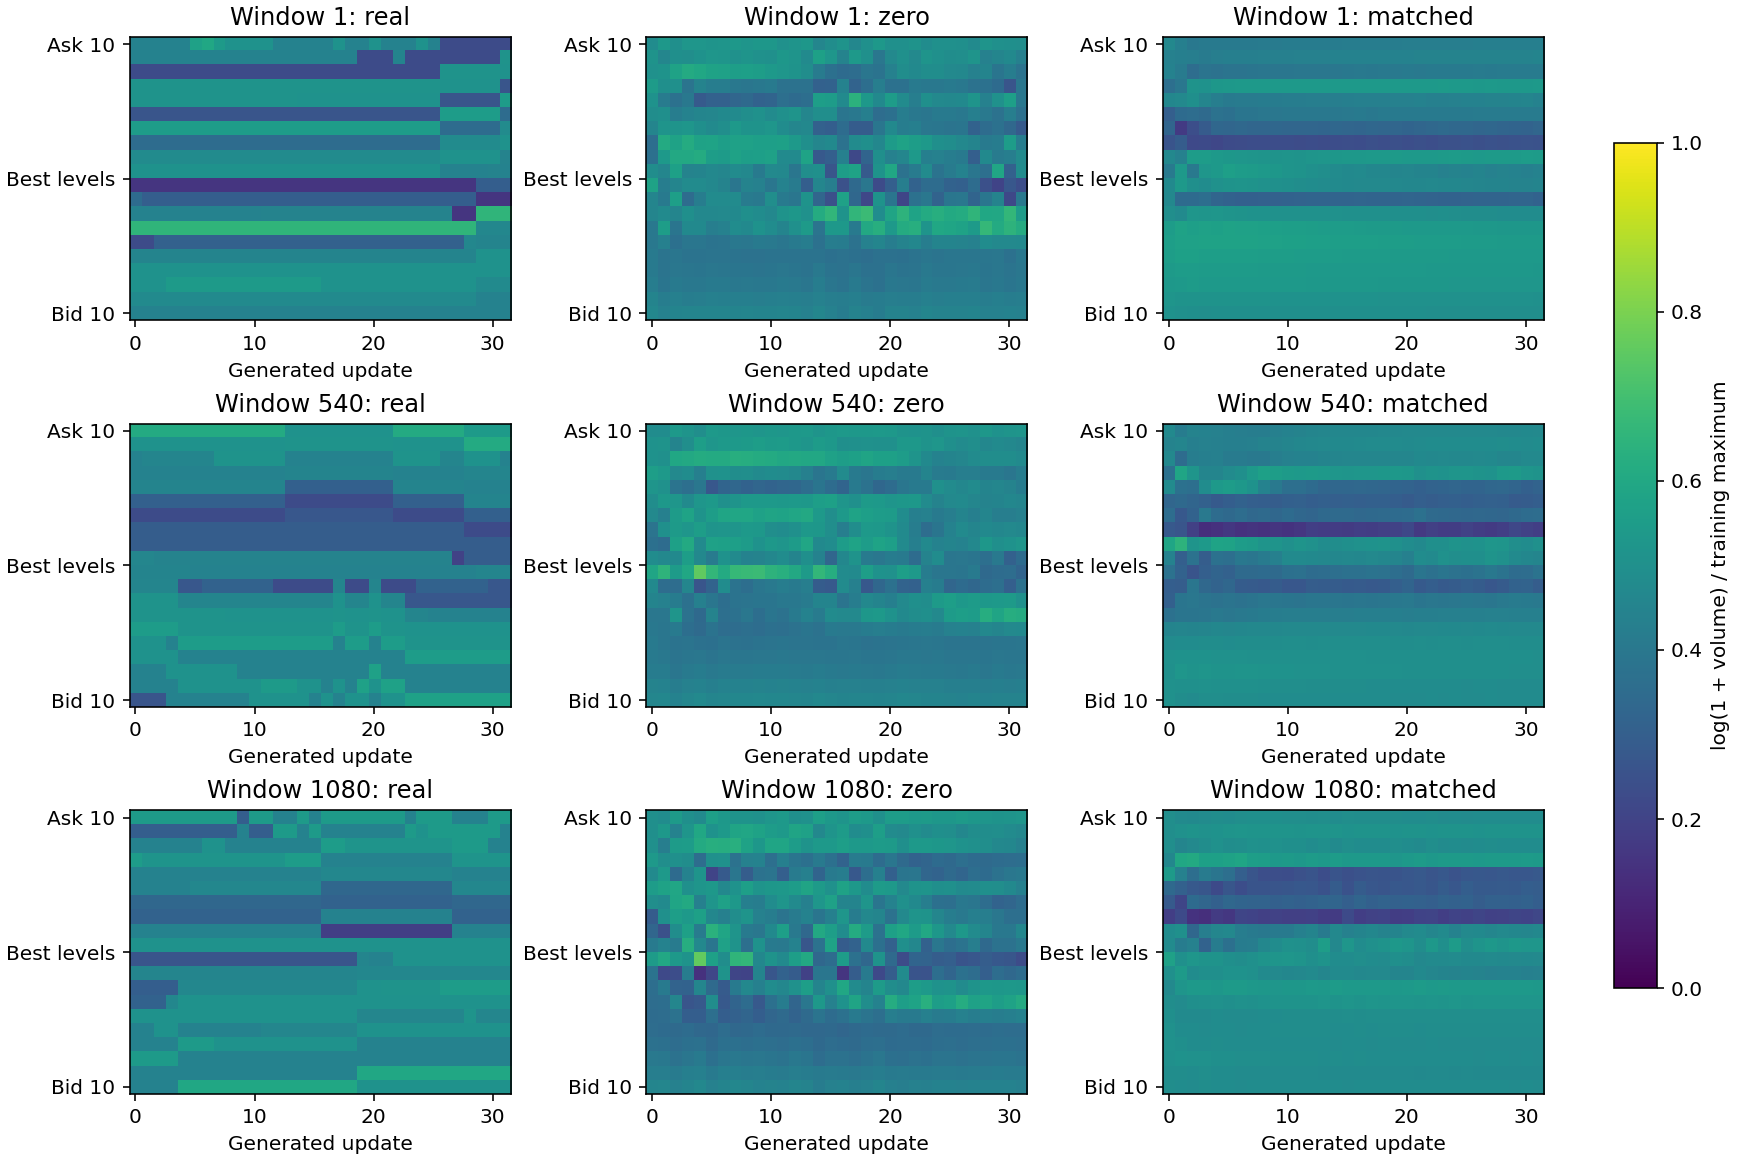

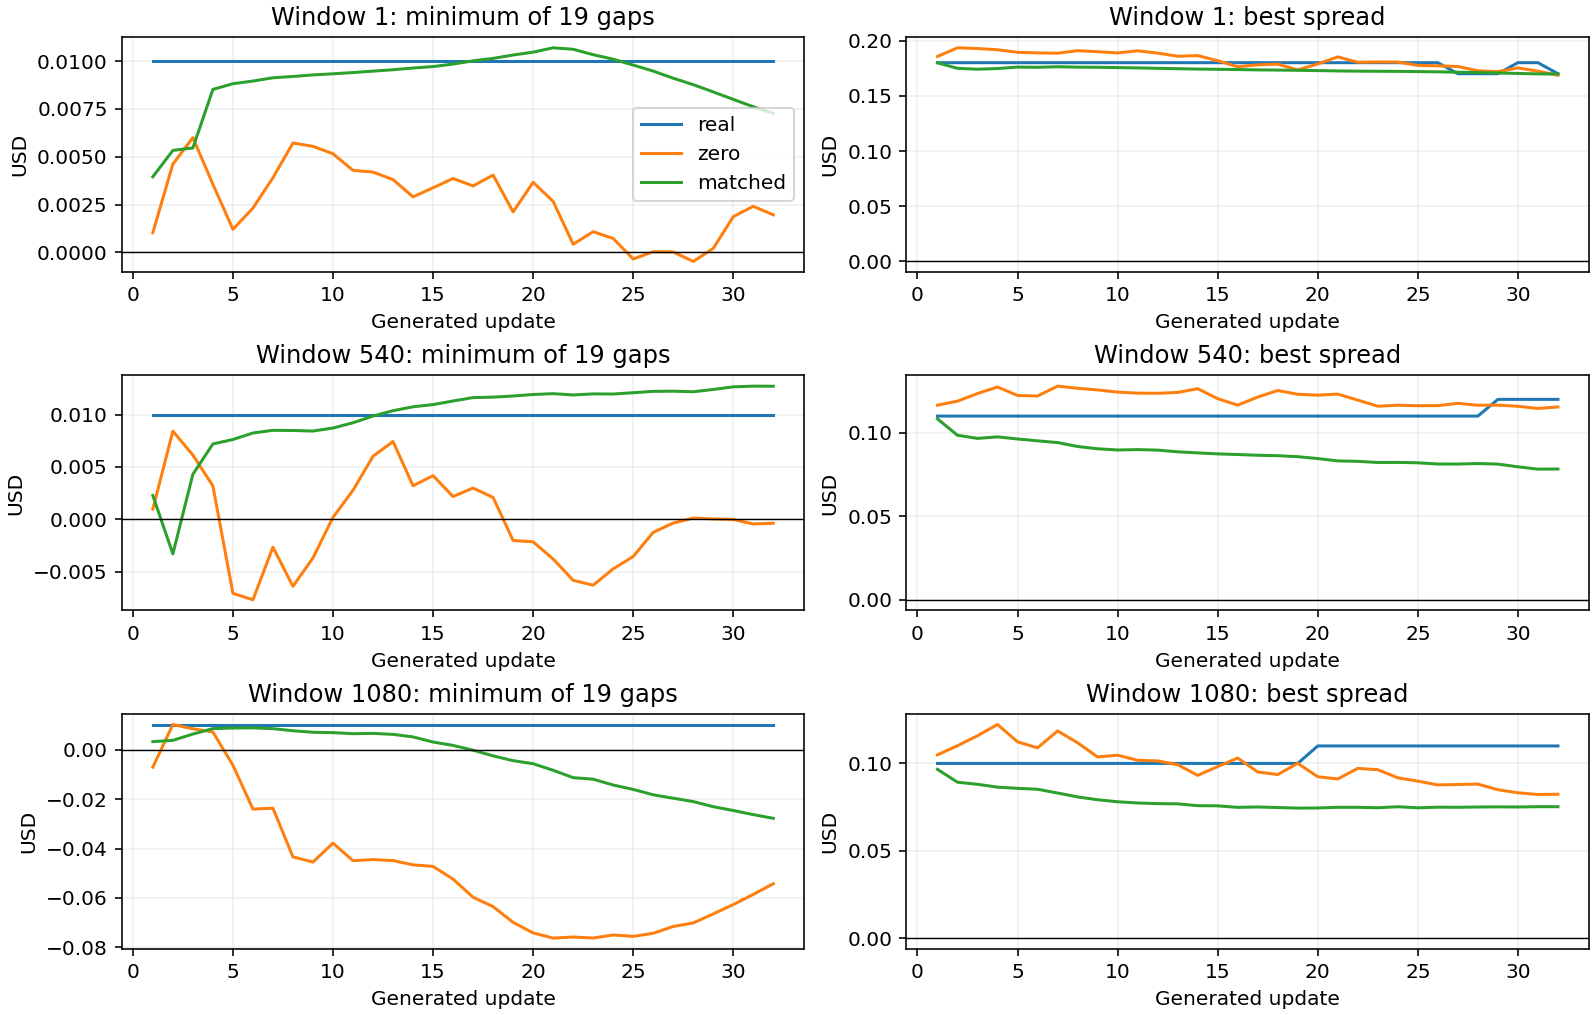

,Parameters,Fit minutes,Generation ms / 1080 windows,Device,Selected joint step
Model,,,,,
TimeGAN: zero context,61361,201.8931,801.2722,cpu,3000.0
TimeGAN: matched context,61361,201.6802,261.1140,cpu,4000.0
VARX(2): zero context,4000,0.0166,25.6664,cpu,NaN
VARX(2): matched context,4000,0.0197,26.5543,cpu,NaN


,mean_joint_seconds,sd_joint_seconds,cycles
mode,,,
none,0.6342,0.0271,20
zero,0.7689,0.2019,20
matched,0.8572,0.0557,20


One CPU worker/thread, same first 128 training windows, 3 warm-up and 20 timed joint cycles, temporary discarded models. No validation quality selection; system activity can affect timings.
Verification: {'project_tests_passed': 61, 'previous_default_updates_exact': True, 'historical_checkpoints_replayed_exactly': 20, 'matched_and_zero_integration_passed': True, 'configuration_reuse_and_mismatch_checked': True, 'checkpoint_replays': {'context_zero_s2026': 0.0, 'context_matched_s2026': 0.0}, 'finite_outputs': True, 'test_evaluated': False, 'context_statistics_match_training_and_ar': True}
Decision: Pilot screen not met: retain the negative/trade-off evidence; do not expand this configuration into a blind grid or call it a validated simulator.


In [4]:
display(pd.DataFrame(conditioning["cases"]).set_index(["Validation window", "Model"]).round(5))
conditioning_figure("depth")
conditioning_figure("gaps")
display(pd.DataFrame(conditioning["resources"]).set_index("Model").round(4))
display(pd.DataFrame(conditioning["performance_check"]["rows"]).set_index("mode").round(4))
print(conditioning["performance_check"]["scope"])
print("Verification:", conditioning["verification"])
print("Decision:", conditioning["next_step"])


## 1. Earlier anchor-only validation comparison

Each TimeGAN mean averages three independent training seeds, each evaluated with generation seeds 42/43/44.
Bars and ± values describe retraining SD, not a confidence interval. The AR fit is deterministic; its displayed SD is generation noise only.
No run is selected by its training seed. Lower is better except SSIM.
Checkpoint selection prioritises validation invalidity, then mean KL, ACF error and earlier step as tie-breakers.

Metric,ACF error,Depth SSIM,Invalid (%),Return KL,Spread KL
Model,,,,,
Gentle order penalty,0.1023 +/- 0.1134,0.1229 +/- 0.0062,39.3991 +/- 3.4528,0.7444 +/- 0.0650,0.2662 +/- 0.1091
Moderate order penalty,0.3010 +/- 0.2299,0.1274 +/- 0.0021,37.5698 +/- 4.6582,0.9100 +/- 0.0555,0.2334 +/- 0.0172
No temporal supervision,0.3667 +/- 0.3304,0.1119 +/- 0.0082,80.8282 +/- 5.0934,0.8160 +/- 0.1262,0.0989 +/- 0.0547
Reference,0.1254 +/- 0.1564,0.1157 +/- 0.0116,72.0570 +/- 6.2407,0.7746 +/- 0.0798,0.0745 +/- 0.0040


,AR model,Invalid (%),Spread KL,Return KL,ACF error,Depth SSIM
0,p2_ridge0.01,93.0160 ± 0.0986,0.1678 ± 0.0242,0.5327 ± 0.0054,0.0295 ± 0.0015,0.1512 ± 0.0020


AR uncertainty above is across generation seeds only; it is not the training SD used for TimeGAN.
Removing supervision changed invalidity from 72.06% to 80.83%; invalidity improved in 1/3 matched seeds. Return KL changed from 0.775 to 0.816, and ACF error from 0.125 to 0.367. These are validation-selected checkpoints under equal reconstruction/joint budgets, with the supervised stage omitted in the ablation. Removing supervision worsened mean invalidity and temporal error, so the supervised reference is retained. Three training seeds and one stock/day limit generalisation; this does not establish a book-validity guarantee.


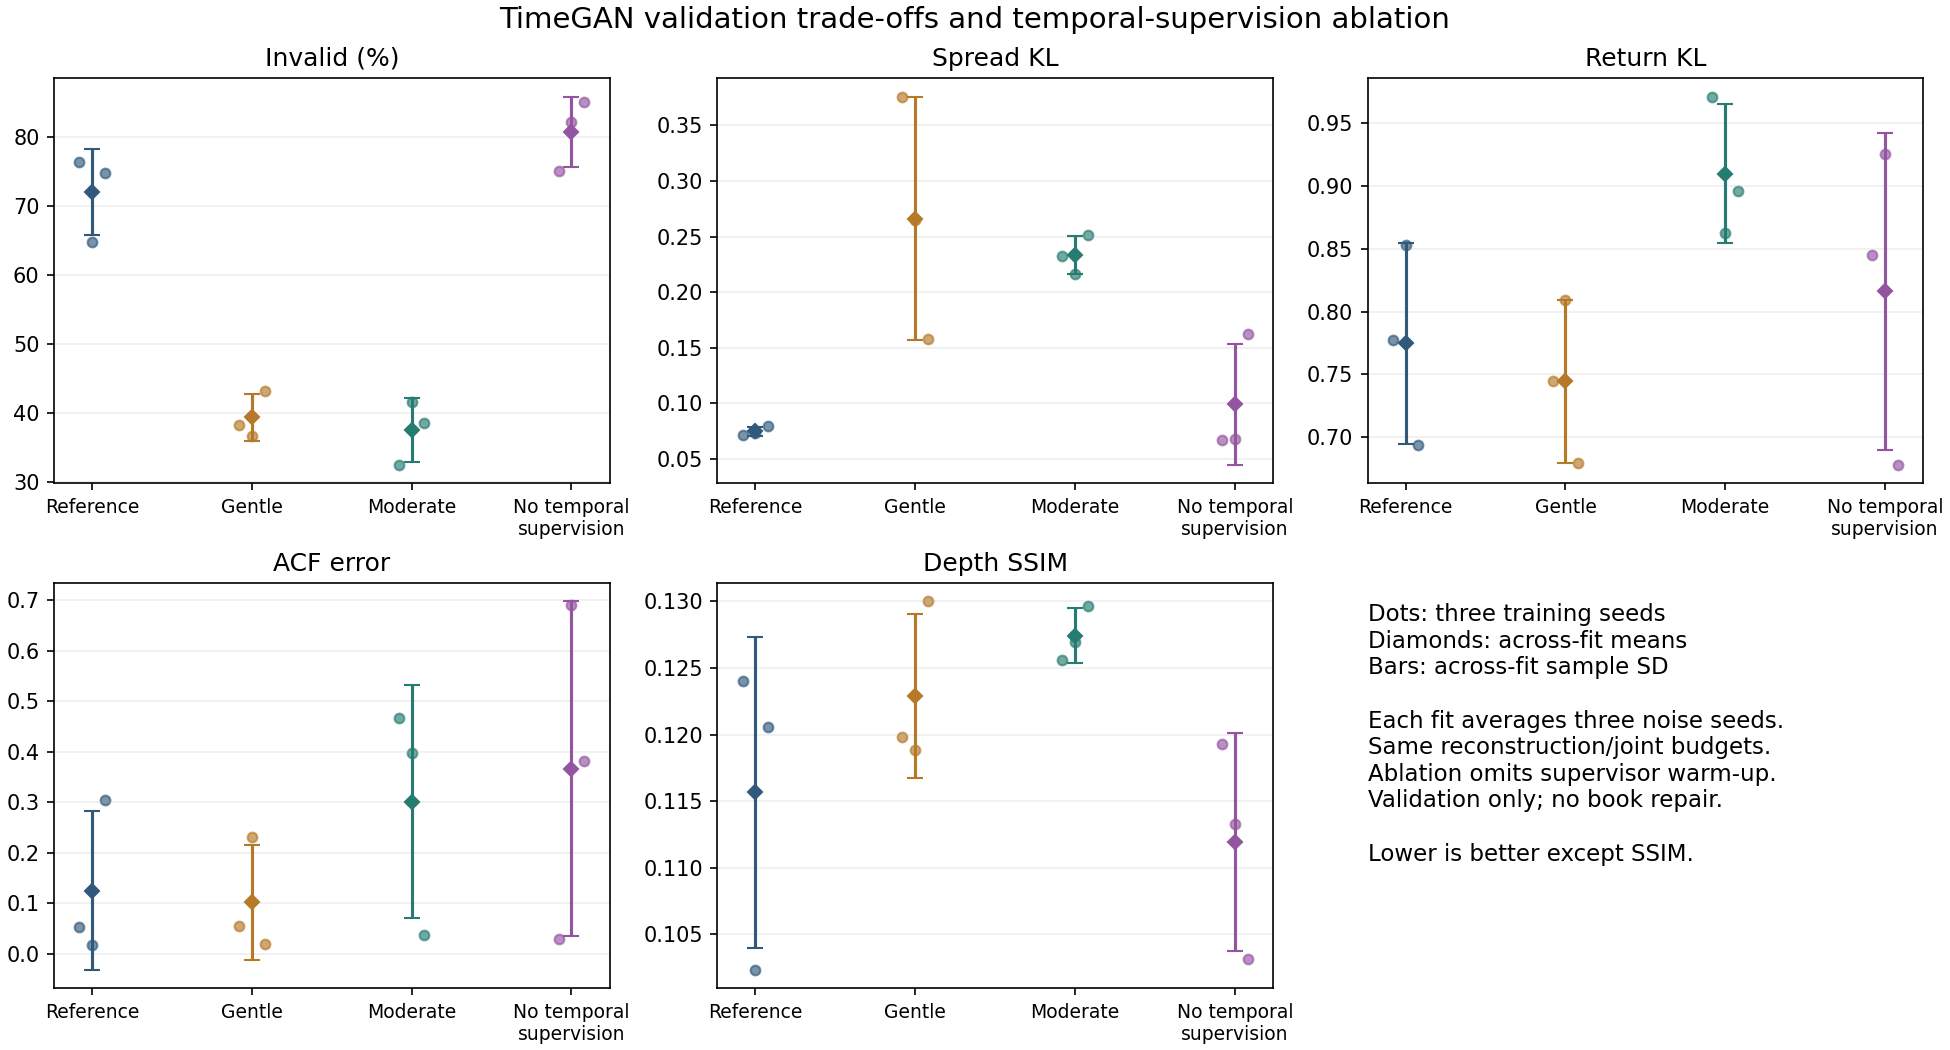

In [5]:
review = tuning["review_comparison"]
current_table = pd.DataFrame(review["training_seed_summary"])
current_table["Mean +/- training SD"] = current_table.apply(lambda r: f"{r.Mean * scales[r.Metric]:.4f} +/- {r.SD * scales[r.Metric]:.4f}", axis=1)
display(current_table.pivot(index="Model", columns="Metric", values="Mean +/- training SD").rename(columns=labels))
ar = json.loads((project / "reports/ar/results.json").read_text())
ar_fit = next(row for row in ar["candidates"] if row["candidate"] == ar["selected_candidate"])
display(pd.DataFrame([[ar_fit["candidate"], *[mean_sd(ar_fit, key, scale) for key, _, scale in metrics]]], columns=["AR model", *labels.values()]))
print("AR uncertainty above is across generation seeds only; it is not the training SD used for TimeGAN.")
print(review["conclusion"])
fig = review["figure"]
image_path = project / "reports/timegan" / fig["file"]
assert hashlib.sha256(image_path.read_bytes()).hexdigest() == fig["sha256"]
display(Image(filename=str(image_path), width=1100))

## 2. Temporal-supervision ablation

Motivation: [TimeGAN Section 5.3](https://proceedings.neurips.cc/paper_files/paper/2019/file/c9efe5f26cd17ba6216bbe2a7d26d490-Paper.pdf).
Remove supervisor pretraining and both joint temporal terms, retaining all five released-code networks and the moment/adversarial losses.
Reference: 5,000/5,000/5,000 updates. Ablation: 5,000/0/5,000 actual updates. Skipped warm-up draws keep joint minibatches paired.
This isolates the supervision component at the same joint budget; it does not match total computation or exactly reproduce the paper's architecture.

At the fixed final step, removing supervision raises mean invalidity from 73.48% to 83.00% and ACF error from 0.153 to 0.342.
The same directional conclusion therefore holds without checkpoint selection; depth SSIM is nearly unchanged at that step.

![Implemented reference architecture and supervision path](reports/timegan/architecture.png)

In [6]:
ablation = tuning["supervision_ablation"]
print("Completed training seeds:", ablation["completed_training_seeds"])
display(pd.DataFrame(ablation["paired_differences"]).set_index("Training seed").round(5))
print("Differences = ablation minus matched reference; positive is worse except for depth SSIM.")
noise = pd.DataFrame(ablation["generation_seed_summary"])
noise["Mean +/- generation SD"] = noise.apply(lambda r: f"{r.Generation_mean * scales[r.Metric]:.4f} +/- {r.Generation_SD * scales[r.Metric]:.4f}", axis=1)
display(noise.pivot(index=["Model", "Training_seed"], columns="Metric", values="Mean +/- generation SD").rename(columns=labels))
print(ablation["interpretation"])
print("Selected joint steps:")
display(pd.DataFrame(ablation["selected_steps"]).pivot(index="Training_seed", columns="Model", values="Selected_step"))
final_step = pd.DataFrame(ablation["final_step_summary"])
final_step["Mean +/- training SD"] = final_step.apply(lambda r: f"{r.Mean * scales[r.Metric]:.4f} +/- {r.SD * scales[r.Metric]:.4f}", axis=1)
print("Sensitivity check at the fixed final joint step (5,000), before checkpoint selection:")
display(final_step.pivot(index="Model", columns="Metric", values="Mean +/- training SD").rename(columns=labels))

Completed training seeds: [2026, 2027, 2028]


,Invalid (%) change,Spread KL change,Return KL change,ACF error change,Depth SSIM change
Training seed,,,,,
2026,-1.19502,-0.00455,0.06789,-0.02461,-0.00469
2027,17.28781,-0.00543,0.07208,0.67186,0.01096
2028,10.22087,0.08295,-0.01583,0.07665,-0.01744


Differences = ablation minus matched reference; positive is worse except for depth SSIM.


Metric                                         ACF error         Depth SSIM  \
Model                   Training_seed                                         
No temporal supervision 2026           0.0292 +/- 0.0018  0.1193 +/- 0.0009   
                        2027           0.6895 +/- 0.0038  0.1133 +/- 0.0046   
                        2028           0.3815 +/- 0.0139  0.1032 +/- 0.0052   
Reference               2026           0.0538 +/- 0.0041  0.1240 +/- 0.0015   
                        2027           0.0176 +/- 0.0008  0.1024 +/- 0.0017   
                        2028           0.3049 +/- 0.0036  0.1206 +/- 0.0018   

Metric                                        Invalid (%)          Return KL  \
Model                   Training_seed                                          
No temporal supervision 2026           75.1919 +/- 1.5410  0.8451 +/- 0.0092   
                        2027           82.1914 +/- 0.3443  0.9251 +/- 0.0495   
                        2028           85.1013 +/- 0.1483  0.6777 +/- 0.0461   
Reference               2026           76.3870 +/- 0.4467  0.7772 +/- 0.0047   
                        2027           64.9035 +/- 0.6751  0.8530 +/- 0.0057   
                        2028           74.8804 +/- 0.8140  0.6935 +/- 0.0169   

Metric                                         Spread KL  
Model                   Training_seed                     
No temporal supervision 2026           0.0669 +/- 0.0034  
                        2027           0.0677 +/- 0.0090  
                        2028           0.1620 +/- 0.0037  
Reference               2026           0.0714 +/- 0.0068  
                        2027           0.0732 +/- 0.0019  
                        2028           0.0790 +/- 0.0089

Removing supervision changed invalidity from 72.06% to 80.83%; invalidity improved in 1/3 matched seeds. Return KL changed from 0.775 to 0.816, and ACF error from 0.125 to 0.367. These are validation-selected checkpoints under equal reconstruction/joint budgets, with the supervised stage omitted in the ablation. Removing supervision worsened mean invalidity and temporal error, so the supervised reference is retained. Three training seeds and one stock/day limit generalisation; this does not establish a book-validity guarantee.
Selected joint steps:


Model,No temporal supervision,Reference
Training_seed,,
2026,4000,5000
2027,3000,5000
2028,5000,4000


Sensitivity check at the fixed final joint step (5,000), before checkpoint selection:


Metric,ACF error,Depth SSIM,Invalid (%),Return KL,Spread KL
Model,,,,,
No temporal supervision,0.3417 +/- 0.2984,0.1159 +/- 0.0111,82.9951 +/- 2.1104,0.7581 +/- 0.0696,0.2041 +/- 0.1447
Reference,0.1526 +/- 0.2032,0.1156 +/- 0.0116,73.4844 +/- 7.5598,0.7474 +/- 0.1233,0.0978 +/- 0.0443


## 3. Three fixed validation cases

Gentle penalty, training seed 2026 and noise seed 42. Choose the first, middle and last eligible windows before inspecting outcomes.
These cases cover different validation periods and are not a best-seed sample. The historical consecutive examples remain below.

,validation_window,invalid_rate,crossed_rate,depth_ssim,minimum_price_gap_usd,real_volume_changes,generated_volume_changes
case,,,,,,,
1,1,0.84375,0.00000,-0.10250,-0.04785,49,620
2,540,0.59375,0.09375,0.16413,-0.00738,92,620
3,1080,0.00000,0.00000,0.19644,0.00148,65,620


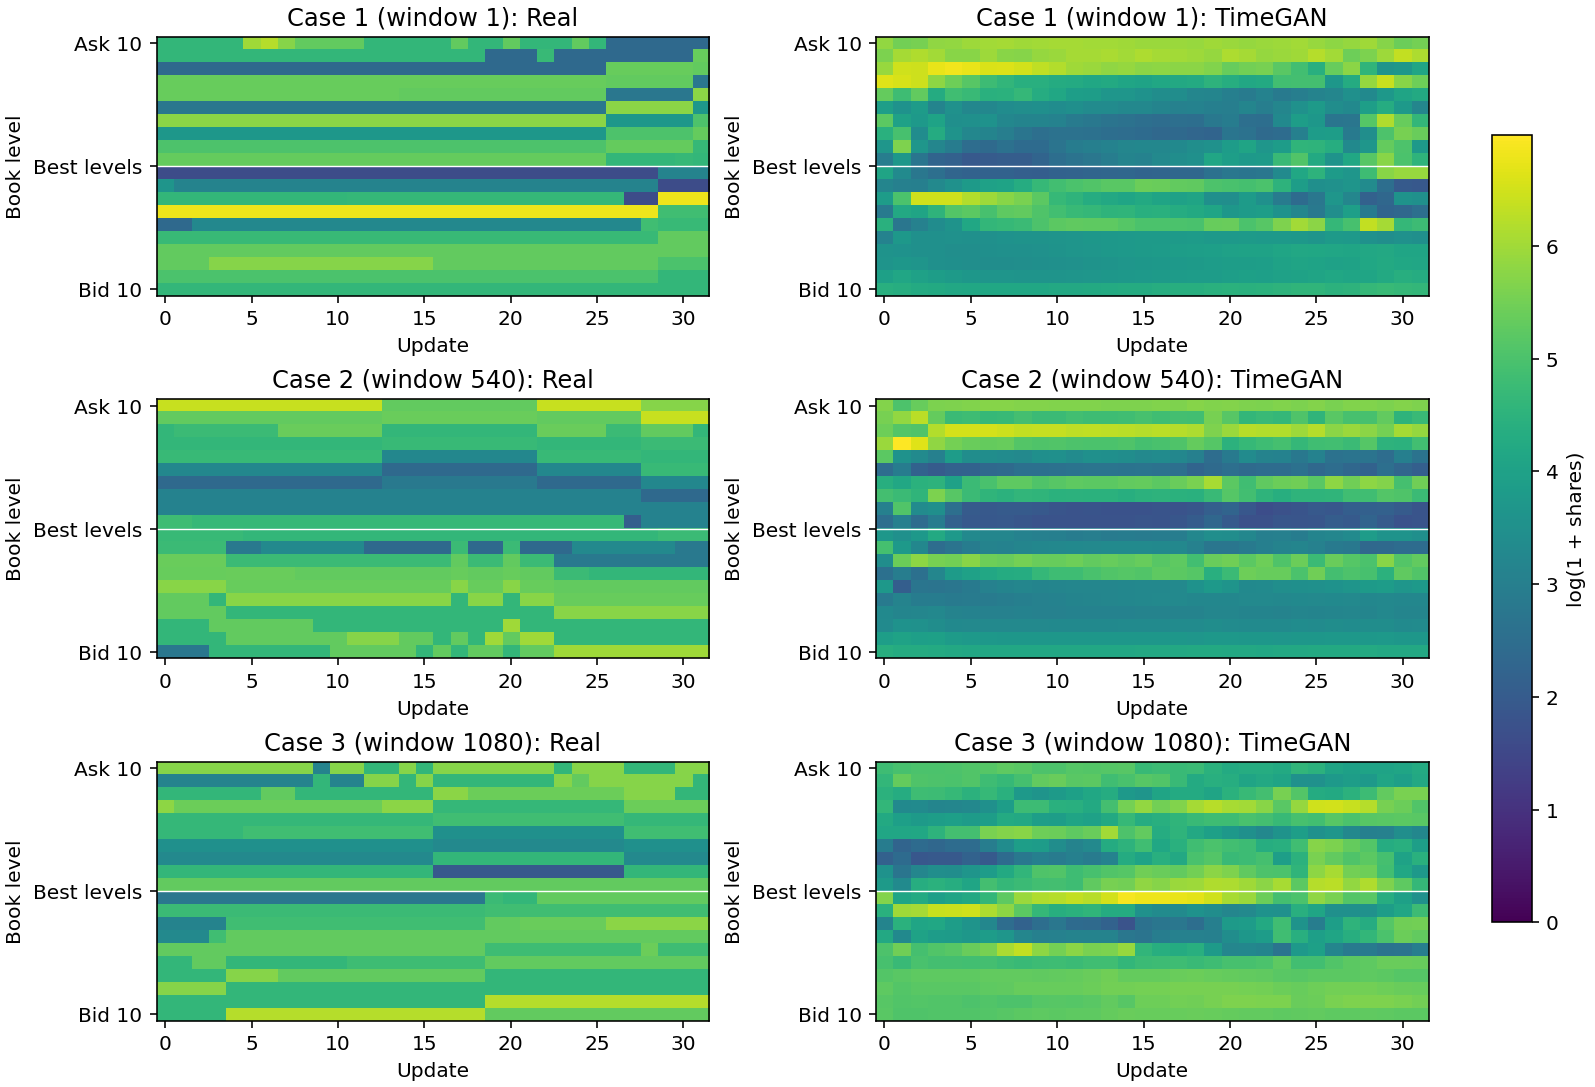

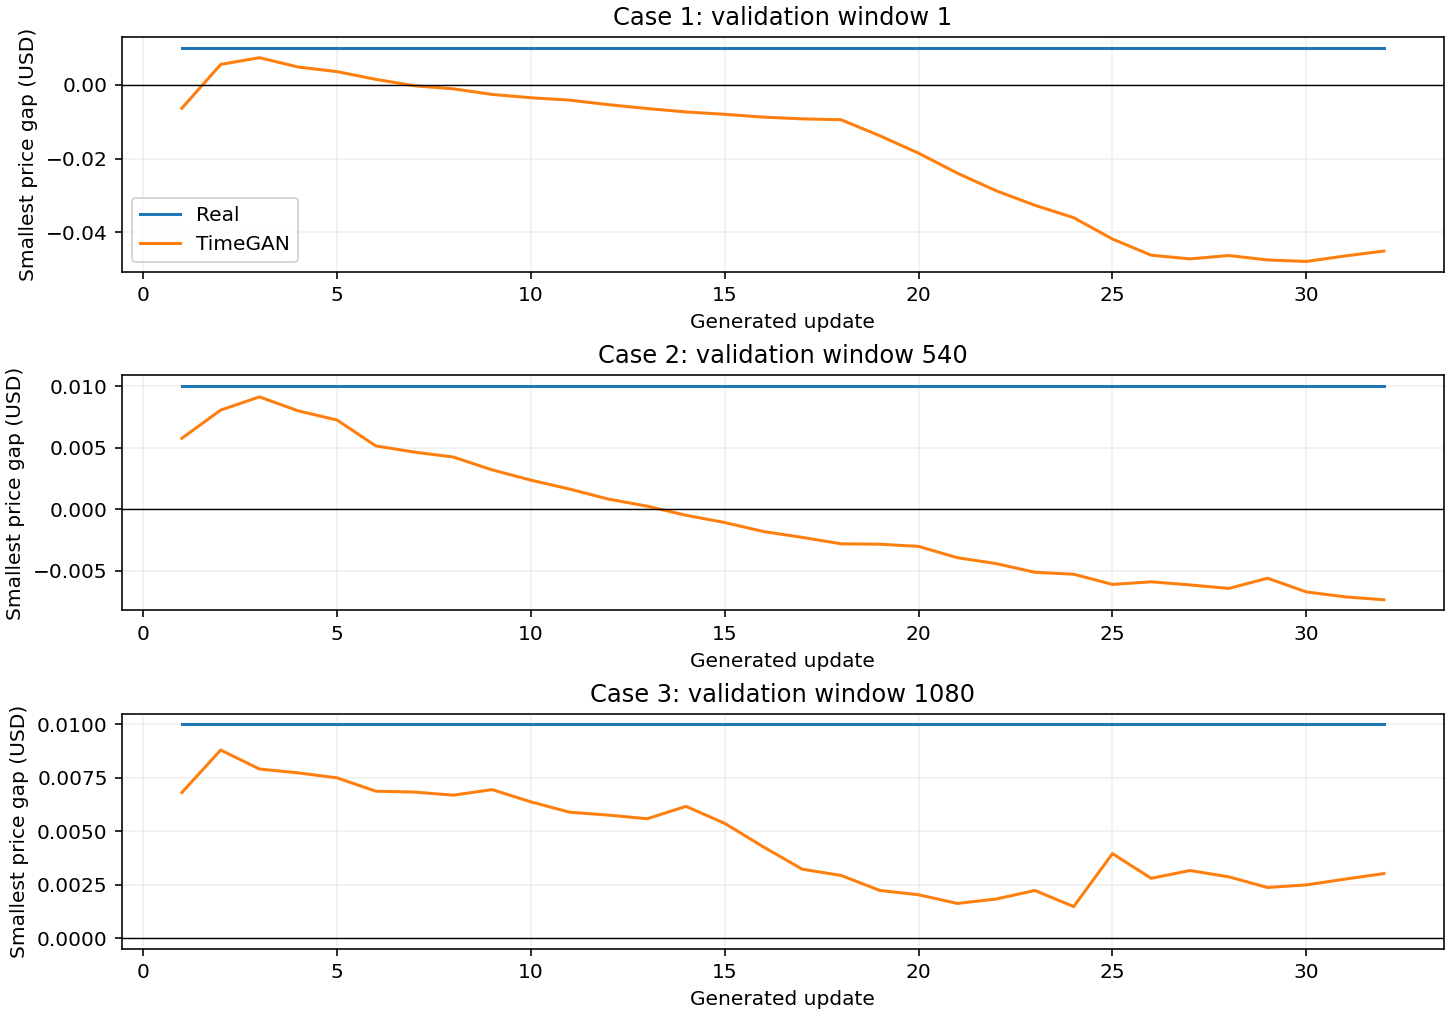

In [7]:
audit = tuning["coverage_audit"]
cases = pd.DataFrame(audit["cases"])
display(cases[["case", "validation_window", "invalid_rate", "crossed_rate", "depth_ssim", "minimum_price_gap_usd", "real_volume_changes", "generated_volume_changes"]].set_index("case").round(5))
for role in ("depth", "price_gaps"):
    fig = audit["figures"][role]
    path = project / audit["directory"] / fig["file"]
    assert hashlib.sha256(path.read_bytes()).hexdigest() == fig["sha256"]
    display(Image(filename=str(path), width=1050))

Case 1 has deeper price-order failures despite positive best spreads. Case 2 has both ask-order and crossed-quote failures.
Case 3 has valid prices throughout, but poor depth similarity. Validity is necessary and insufficient.

Generated volumes change in all 620 within-window feature transitions in each case, versus 49/92/65 real changes.
This counts exact numerical changes, not changes above an economic threshold. The heatmaps expose smooth dense updates where real books often stay unchanged.
Price-gap drift is consistent with accumulated level-specific return errors; it does not establish a single training cause.

The anchor control gives 0% invalidity for real returns with their own starting prices, versus 59.77% with cyclically shifted starting books.
This exposes an input-information mismatch: the earlier generator does not observe initial price gaps. The new controlled conditioning study above tests this hypothesis.

## 4. Resources and review checks

The earlier anchor-only TimeGAN runs use the same 54,521-parameter architecture. CPU runs have no GPU allocation measurement.
Concurrent-fit timings are descriptive, not isolated hardware benchmarks. Generation excludes decoding and metrics.
TimeGAN run times include preparation and validation; the AR row reports fitting only and excludes its residual bank from parameter counts.
The older GPU pilot used a different architecture; its memory reading is not transferred to these CPU fits.

In [8]:
display(pd.DataFrame(tuning["review_comparison"]["resources"]).set_index("Model").round(4))
verification = ablation["verification"]
print("Project tests at the supervision-ablation review:", verification["project_tests_passed"])
print("Previous default updates identical:", verification["previous_default_updates_exact"])
print("Ablation integration/reload/configuration checks:", verification["full_ablation_integration"], verification["checkpoint_reload_max_abs_difference"], verification["configuration_reuse_checked"])
print("Full-fit verification:", ablation["final_verification"])

,Parameters,Fits,Fit minutes mean,Fit minutes SD,Generation ms / 1080 windows,Peak GPU allocation
Model,,,,,,
"VAR(2), fitting only",3240,1,0.0117,NaN,135.4798,N/A (CPU)
Reference,54521,3,66.6461,2.1122,136.2735,N/A (CPU)
Gentle order penalty,54521,3,67.4520,1.3173,172.6248,N/A (CPU)
Moderate order penalty,54521,3,63.3481,1.0795,159.0580,N/A (CPU)
No temporal supervision,54521,3,51.4556,2.2768,152.4040,N/A (CPU)


Project tests at the supervision-ablation review: 52
Previous default updates identical: True
Ablation integration/reload/configuration checks: True 0.0 True
Full-fit verification: {'completed_fits': 3, 'direct_replays': [{'run': 'no_supervision_s2026', 'max_abs_difference': 0.0, 'finite_features': True}, {'run': 'no_supervision_s2027', 'max_abs_difference': 0.0, 'finite_features': True}, {'run': 'no_supervision_s2028', 'max_abs_difference': 0.0, 'finite_features': True}], 'all_candidate_checkpoints_verified': 20, 'source_archives_verified': 20, 'finite_outputs': True, 'test_evaluated': False, 'ar_report_unchanged': True}


### Temporal interpretation control

Shuffling the real returns preserves their marginal distribution while destroying temporal order. It is a diagnostic, not an order-book generator.
Its ACF error (0.0301) is close to AR's (0.0295); low scalar error alone is weak evidence of realistic volatility clustering.
The plot shows mean curves and the range across three training seeds. Inference is restricted to lags 1–10 within 32-update windows.

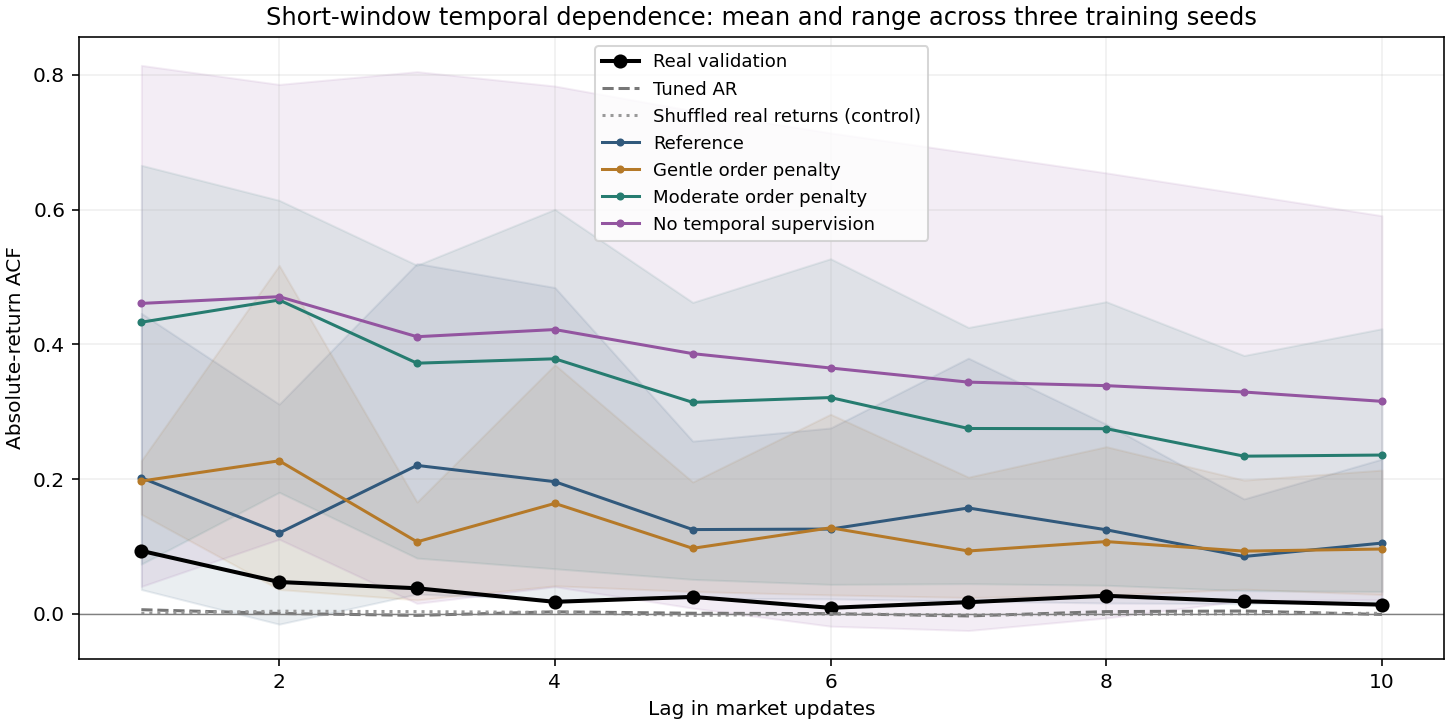

AR has nearly zero absolute-return ACF. A small scalar ACF error on this short-window dataset alone does not demonstrate realistic volatility clustering. Compare the curve with real returns and the shuffled control.


In [9]:
temporal = tuning["temporal_audit"]
path = project / "reports/timegan" / temporal["figure"]["file"]
assert hashlib.sha256(path.read_bytes()).hexdigest() == temporal["figure"]["sha256"]
display(Image(filename=str(path), width=1050))
print(temporal["interpretation"])

## Appendix: reference audit and complete experiment history

The following sections retain the early 1,000-per-stage reference, previous pilot comparisons and all tuning attempts.
Their measurements apply to those labelled runs. The current comparisons above take precedence for the overall conclusion.

### 1. Method and reference audit

We follow the [authors' released code](https://github.com/jsyoon0823/TimeGAN/blob/8f6181cb9b9d2fa0c930cd902411d9ac8a308e07/timegan.py).
Five unidirectional GRU networks: embedder, recovery, generator, supervisor and discriminator. The supervisor has one fewer layer.
Training uses reconstruction, supervisor pretraining and joint adversarial/moment learning, with two G/E updates per D opportunity.

The review separated warm-up and joint embedding Adam states, removed the pilot's clipping and extra root epsilon, and replaced the
built-in PyTorch GRU with the TensorFlow-1-style reset-before-matrix equations and initialisation. Reconstruction and supervision
now use the reference square roots without extra epsilon; the reference moment variance epsilon of 1e-6 remains.

The [paper](https://proceedings.neurips.cc/paper_files/paper/2019/file/c9efe5f26cd17ba6216bbe2a7d26d490-Paper.pdf) illustrates feedforward
recovery, a bidirectional discriminator and Wiener noise. The released code uses recurrent recovery, a unidirectional discriminator
and uniform noise, with a separate supervisor. We follow those code choices; see README for the full audit table.

This is a PyTorch structural port, not a bitwise TensorFlow reproduction. Adam epsilon placement, RNG and kernels differ. We retain
32-update LOB features, chronological splits, the shared training-only scaler and assignment metrics. The released demo instead
uses 24 updates and 50,000 iterations per stage. Our scaler omits its 1e-7 span offset to preserve the established AR contract.

Both models use `anchor_only_v1`: the same 1,080 validation windows, starting prices, 32 updates and generation seeds. No validation
features or volumes enter generation. No clipping, sorting, future matching or structural repair is applied.

In [10]:
facts = [("Architecture", config["architecture"]), ("Batch size", config["batch_size"]), ("Learning rate", config["learning_rate"]),
         ("Training seed", config["training_seed"]), ("Generation seeds", config["generation_seeds"]),
         ("Stage update counts", [config[k] for k in ("embedding_steps", "supervised_steps", "joint_steps")]),
         ("Generator updates per joint step", config["generator_updates_per_joint_step"]), ("Device", report["device_name"])]
display(pd.DataFrame(facts, columns=["Setting", "Value"]).set_index("Setting"))
for i, previous in enumerate(report.get("previous_runs", [])):
    old = previous["config"]
    print(f"Earlier run {i + 1}: {old['architecture']}, batch {old['batch_size']}, "
          f"stage budgets {[old[k] for k in ('embedding_steps', 'supervised_steps', 'joint_steps')]}")
if min(config[k] for k in ("embedding_steps", "supervised_steps", "joint_steps")) < 1000:
    print("Short integration budget: these results do not establish an improvement over the longer pilot.")

,Value
Setting,
Architecture,"{'features': 40, 'hidden': 24, 'layers': 3, 'n..."
Batch size,128
Learning rate,0.001
Training seed,2026
Generation seeds,"[42, 43, 44]"
Stage update counts,"[1000, 1000, 1000]"
Generator updates per joint step,2
Device,CPU


Earlier run 1: {'features': 40, 'hidden': 32, 'layers': 2, 'noise_dim': 40}, batch 64, stage budgets [1000, 500, 1000]
Earlier run 2: {'features': 40, 'hidden': 24, 'layers': 3, 'noise_dim': 40, 'cell': 'reference'}, batch 128, stage budgets [100, 100, 100]


### 2. Checks before and after training

A separate model learns eight windows drawn across training. Its reconstruction error must fall below half its initial error and
below a constant-feature predictor. These weights are discarded before the main run. Tests also check temporal alignment, the
networks updated by each optimiser, adversarial gradient flow, causal generation and local random seeds.

After validation selection, the saved checkpoint is reloaded and must reproduce the first three reported examples.

In [11]:
check = report["reconstruction_check"]
display(pd.DataFrame([[check["initial_mse"], check["constant_feature_mean_mse"], check["final_mse"], check["steps"], check["passed"]]],
                     columns=["Initial MSE", "Constant predictor MSE", "Final MSE", "Updates", "Passed"]).round(7))
print("Largest decoded-example difference after reload:", report["reload_max_abs_difference"])

,Initial MSE,Constant predictor MSE,Final MSE,Updates,Passed
0,0.024826,0.010554,0.00307,600,True


Largest decoded-example difference after reload: 0.0


### 3. Training behaviour

Each recorded loss is from that step's training batch; joint generator/embedding values average two updates. Losses have different
scales and roles. Decreasing loss or plausible discriminator probabilities do not establish realistic books.

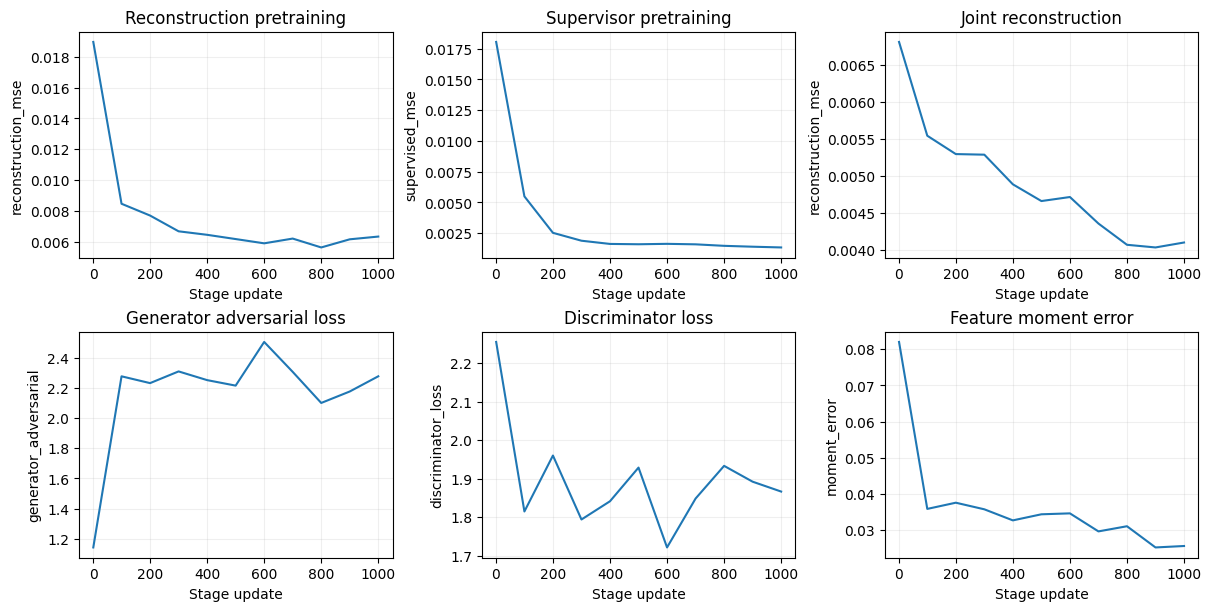

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6), layout="constrained")
plots = [("embedding", "reconstruction_mse", "Reconstruction pretraining"), ("supervised", "supervised_mse", "Supervisor pretraining"),
         ("joint", "reconstruction_mse", "Joint reconstruction"), ("joint", "generator_adversarial", "Generator adversarial loss"),
         ("joint", "discriminator_loss", "Discriminator loss"), ("joint", "moment_error", "Feature moment error")]
for ax, (stage, metric, title) in zip(axes.flat, plots):
    rows = history[history.stage == stage]
    ax.plot(rows.step, rows[metric]); ax.set(title=title, xlabel="Stage update", ylabel=metric); ax.grid(alpha=.2)
plt.show()

### 4. Validation checkpoint selection and AR comparison

Selection minimises seed-mean invalid rate, then mean KL, then ACF error; an earlier checkpoint breaks remaining ties. SSIM is
reported but not used for selection. These are validation results after checkpoint selection, not unbiased final test scores.

In [13]:
fields = ["step", "invalid_rate_mean", "kl_spread_mean", "kl_mid_return_mean", "abs_return_acf_mae_mean", "depth_ssim_mean"]
table = validation[fields].copy()
table["invalid_rate_mean"] *= 100
table.columns = ["Joint step", "Invalid (%)", "Spread KL", "Return KL", "ACF error", "Depth SSIM"]
display(table.round(5).set_index("Joint step"))
print("Selected joint step:", selected["step"])
metrics = [("invalid_rate", "Invalid (%)", 100), ("kl_spread", "Spread KL", 1), ("kl_mid_return", "Return KL", 1),
           ("abs_return_acf_mae", "ACF error", 1), ("depth_ssim", "Depth SSIM", 1)]
def run_label(run):
    cfg = run["config"]
    cell_type = "Reference" if cfg["architecture"].get("cell") == "reference" else "Original GPU pilot"
    counts = "/".join(str(cfg[k]) for k in ("embedding_steps", "supervised_steps", "joint_steps"))
    return f"{cell_type} ({counts})"

models = [(row["candidate"], row) for row in report["ar_baselines"]]
models += [(run_label(row), row["selected"]) for row in report.get("previous_runs", [])]
models += [(run_label(report), selected)]
comparison = [[name, *[mean_sd(row, key, scale) for key, _, scale in metrics]] for name, row in models]
display(pd.DataFrame(comparison, columns=["Model", *[label for _, label, _ in metrics]]).set_index("Model"))


,Invalid (%),Spread KL,Return KL,ACF error,Depth SSIM
Joint step,,,,,
250,99.69618,0.43420,1.03266,0.08348,0.14669
500,97.50772,0.31577,0.75878,0.07145,0.13054
750,99.85532,0.33344,0.91935,0.03148,0.14355
1000,99.71547,0.21206,0.82920,0.06203,0.14895


Selected joint step: 500


,Invalid (%),Spread KL,Return KL,ACF error,Depth SSIM
Model,,,,,
p1_ridge0.0001,93.1491 ± 0.0969,0.1583 ± 0.0062,0.5523 ± 0.0141,0.0188 ± 0.0017,0.1250 ± 0.0027
p2_ridge0.01,93.0160 ± 0.0986,0.1678 ± 0.0242,0.5327 ± 0.0054,0.0295 ± 0.0015,0.1512 ± 0.0020
Original GPU pilot (1000/500/1000),95.6713 ± 0.0494,0.1197 ± 0.0068,0.6970 ± 0.0084,0.1384 ± 0.0049,0.1291 ± 0.0010
Reference (100/100/100),100.0000 ± 0.0000,0.9356 ± 0.0023,0.2451 ± 0.0323,0.4430 ± 0.0059,0.2290 ± 0.0001
Reference (1000/1000/1000),97.5077 ± 0.0546,0.3158 ± 0.0090,0.7588 ± 0.0059,0.0715 ± 0.0037,0.1305 ± 0.0030


Smaller is better except SSIM. The ± values are sample SD across three generation seeds from the same fitted model; they do not
measure independent training runs or different days. SSIM compares numeric log-volume images with fixed training scaling, separately
for bid and ask, using the declared 7×7 uniform-window variant. It does not measure valid price ladders.

In [14]:
criteria = [("Zero invalid snapshots", selected["invalid_rate_mean"] == 0), ("Spread KL ≤ 0.1", selected["kl_spread_mean"] <= .1),
            ("Return KL ≤ 0.1", selected["kl_mid_return_mean"] <= .1), ("Depth SSIM > 0.6", selected["depth_ssim_mean"] > .6)]
display(pd.DataFrame([(label, "Met" if passed else "Not met") for label, passed in criteria], columns=["Criterion", "Current run"]).set_index("Criterion"))
violations = [("crossed_rate", "Nonpositive spread"), ("ask_order_rate", "Unordered asks"), ("bid_order_rate", "Unordered bids"),
              ("negative_volume_rate", "Negative volumes"), ("nonpositive_price_rate", "Nonpositive prices"), ("nonfinite_rate", "Non-finite")]
display(pd.DataFrame([(label, mean_sd(selected, key, 100)) for key, label in violations], columns=["Violation", "Snapshots (%)"]).set_index("Violation"))
control = report["ssim_controls"]
print(f"Depth SSIM controls: real against itself = {control['identity']:.3f}; shuffled real windows = {control['shuffled_real']:.3f}.")
print("The shuffled control illustrates pairing sensitivity. It is not a score ceiling or selection criterion.")


,Current run
Criterion,
Zero invalid snapshots,Not met
Spread KL ≤ 0.1,Not met
Return KL ≤ 0.1,Not met
Depth SSIM > 0.6,Not met


,Snapshots (%)
Violation,
Nonpositive spread,0.0000 ± 0.0000
Unordered asks,95.3906 ± 0.0957
Unordered bids,96.1941 ± 0.0670
Negative volumes,0.0000 ± 0.0000
Nonpositive prices,0.0000 ± 0.0000
Non-finite,0.0000 ± 0.0000


Depth SSIM controls: real against itself = 1.000; shuffled real windows = 0.112.
The shuffled control illustrates pairing sensitivity. It is not a score ceiling or selection criterion.


### 5. Diversity and fixed examples

These are the first three eligible validation windows and the first generation seed, selected before viewing model outputs.
All examples share their observed starting prices with the real sequence. A sample is not a forecast of that particular future.
Exact uniqueness alone does not rule out collapse: nearly identical sequences can still have distinct floating-point values.

Distinct generated feature sequences: 1080 / 1080
Mean between-sequence standard deviation (scaled features): 0.050446


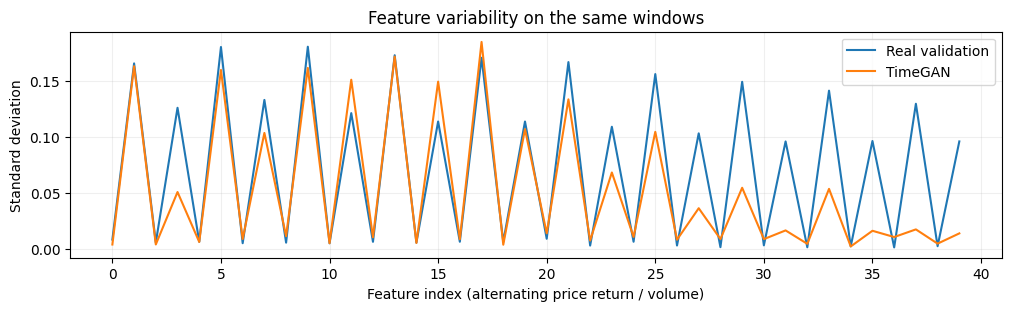

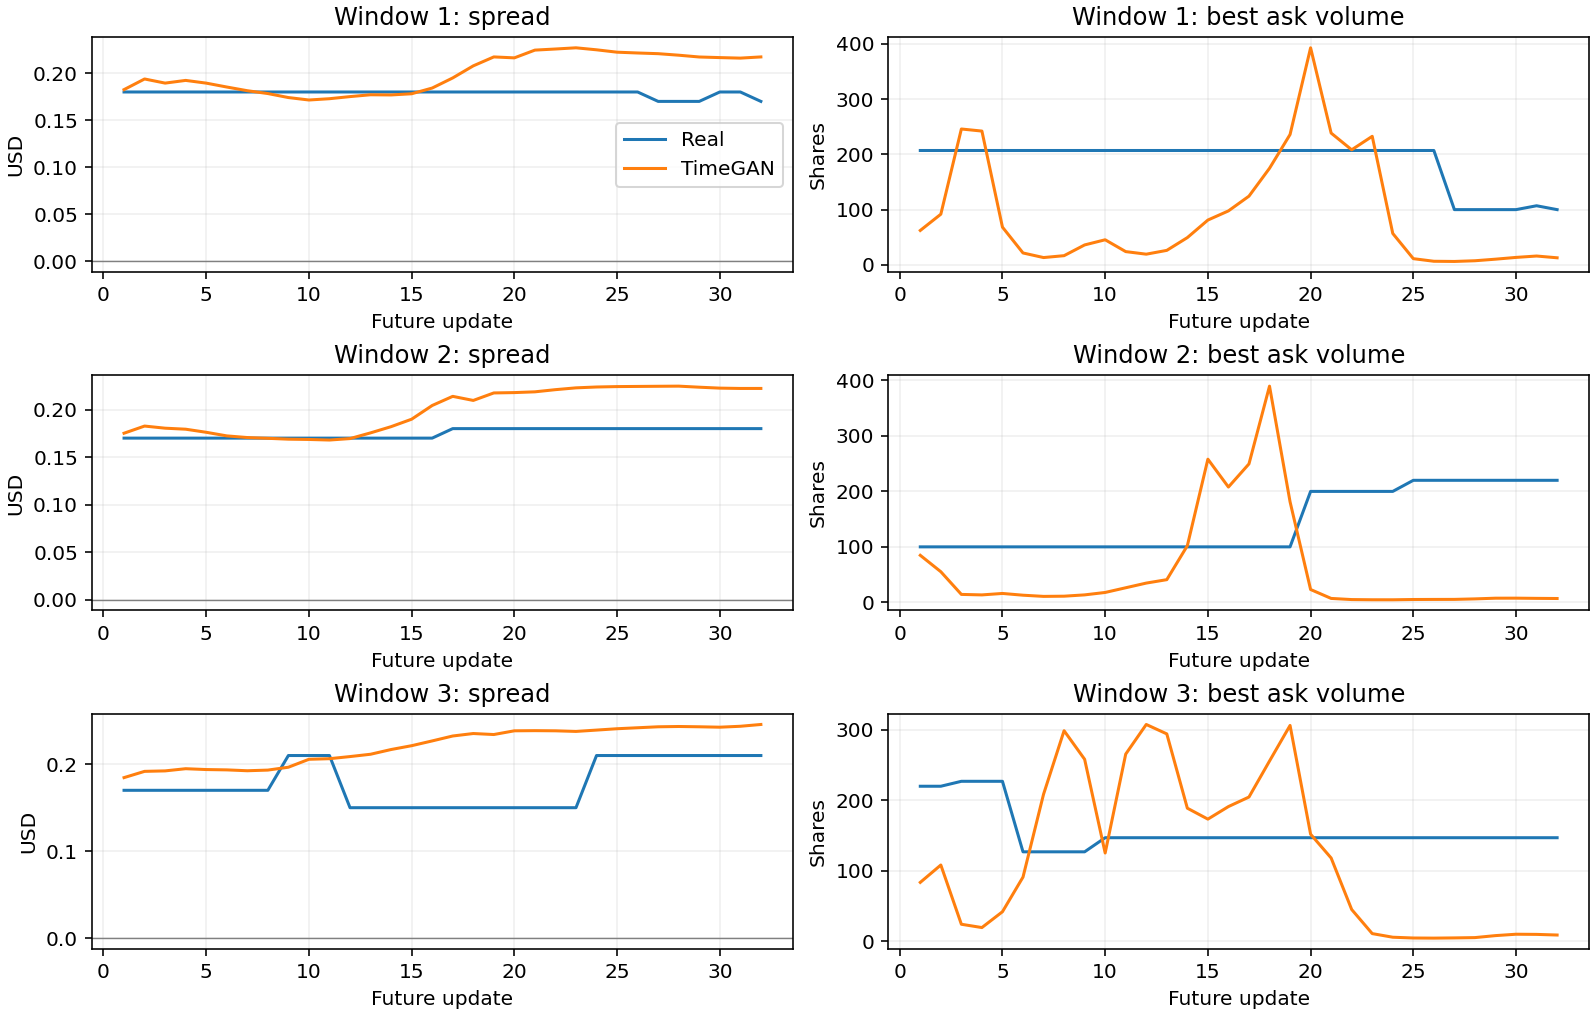

In [15]:
diversity = selected["diversity"]
print(f"Distinct generated feature sequences: {diversity['unique_sequences']} / {report['validation_windows']}")
print(f"Mean between-sequence standard deviation (scaled features): {diversity['mean_between_sequence_std']:.6f}")
fig, ax = plt.subplots(figsize=(10, 3), layout="constrained")
ax.plot(diversity["real_feature_std"], label="Real validation")
ax.plot(diversity["generated_feature_std"], label="TimeGAN")
ax.set(xlabel="Feature index (alternating price return / volume)", ylabel="Standard deviation", title="Feature variability on the same windows")
ax.legend(); ax.grid(alpha=.2); plt.show()
figure("examples")

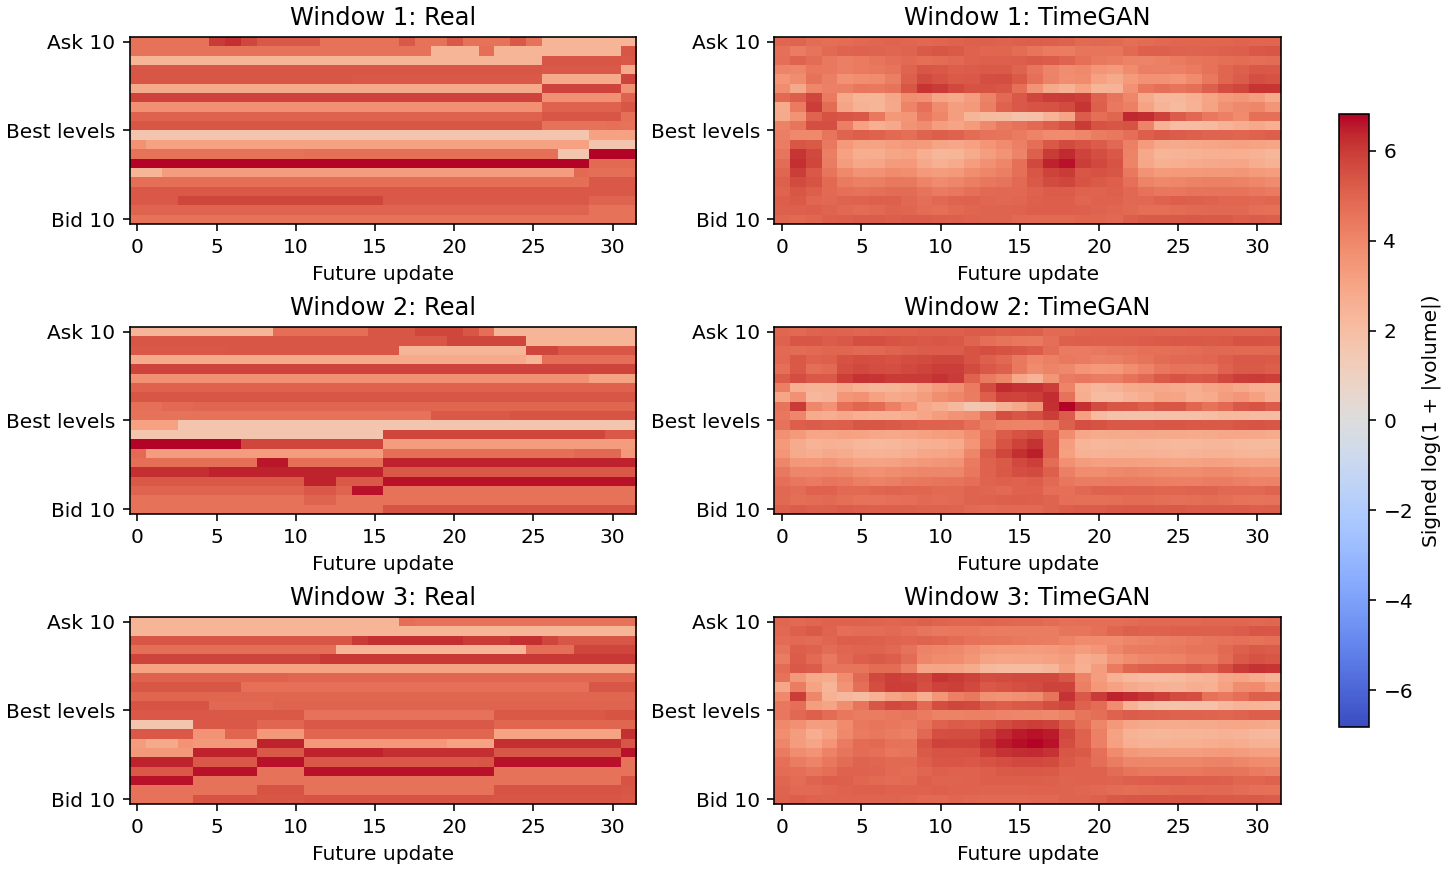

,window,model,invalid_rate,crossed_rate,ask_order_rate,bid_order_rate,depth_ssim
0,1,Real,0.0000,0.0,0.0000,0.0000,1.0000
1,1,TimeGAN,1.0000,0.0,1.0000,1.0000,0.0095
2,2,Real,0.0000,0.0,0.0000,0.0000,1.0000
3,2,TimeGAN,0.9688,0.0,0.9375,0.9688,-0.0339
4,3,Real,0.0000,0.0,0.0000,0.0000,1.0000
5,3,TimeGAN,0.9688,0.0,0.9375,0.9688,0.0822


In [16]:
figure("depth")
diagnostics = pd.DataFrame(report["example_diagnostics"])
display(diagnostics[["window", "model", "invalid_rate", "crossed_rate", "ask_order_rate", "bid_order_rate", "depth_ssim"]].round(4))

### 6. Runtime and efficiency

Current stage timings include training and periodic logging, with device synchronisation at boundaries; validation/checkpoint time
is excluded. Historical pilot timing covered update calls only. Whole-run totals also include loading, the independent reconstruction
check, validation and figures. They are not a controlled speed comparison across different models and budgets.

The strict reference cell cannot use PyTorch's fused GRU. A short same-shape benchmark below motivated CPU/one-thread execution
for the reference experiments. GPU allocation is unavailable for a CPU run. The historical pilot's GPU figures measure PyTorch allocation,
not total driver/context memory. Feature generation timing excludes decoding and evaluation.

Input projections are shared across time; training windows stay on the chosen device; parameter lists and source hashes are cached.
Diagnostics are collected every 100 steps. New runs save selected/final checkpoints, plus the previous selected model for recovery.

In [17]:
resource_rows = [("Data loading and evaluation setup (s)", report["data_loading_seconds"]),
                 ("Separate reconstruction check (s)", report["reconstruction_check"]["seconds"]),
                 *[(stage + " training (s)", seconds) for stage, seconds in report["stage_training_seconds"].items()],
                 ("Whole run before report writing (s)", report["total_seconds"]),
                 ("Peak allocated (GiB)", report["peak_allocated_bytes"] / 1024**3 if report["peak_allocated_bytes"] is not None else None),
                 ("Peak reserved (GiB)", report["peak_reserved_bytes"] / 1024**3 if report["peak_reserved_bytes"] is not None else None),
                 ("Mean generation seconds / 1,080 sequences", selected["generation_seconds_mean"]),
                 ("Approximate feature sequences / second", report["validation_windows"] / selected["generation_seconds_mean"])]
display(pd.DataFrame(resource_rows, columns=["Measurement", "Value"]).set_index("Measurement").round(5))
if "review_benchmark" in report:
    display(pd.DataFrame(report["review_benchmark"]["rows"]).round(4))
    print(report["review_benchmark"]["scope"])

,Value
Measurement,
Data loading and evaluation setup (s),2.76201
Separate reconstruction check (s),35.06284
embedding training (s),104.47315
supervised training (s),43.96971
joint training (s),817.25236
Whole run before report writing (s),1009.44279
Peak allocated (GiB),NaN
Peak reserved (GiB),NaN
"Mean generation seconds / 1,080 sequences",0.20109


,device,cell,seconds_per_joint_step,threads,warmup_updates,timed_updates
0,cpu,pytorch,2.8491,4,2,5
1,cpu,reference,4.6320,4,2,5
2,cuda,pytorch,0.1442,4,2,5
3,cuda,reference,6.9504,4,2,5
4,cpu,reference,4.3392,1,1,2


Synthetic fixed batches; two G/E updates and one D opportunity per joint iteration. Short serial timing samples, not a quality comparison or full-run speedup. Default scripted reference cell; no training data used.


### 7. Reconstruction and anchor diagnostics

These checks use the saved 1,000-update reference checkpoint: 512 evenly spaced training windows and all 1,080 common validation windows.
Reconstruction sends observed features through the encoder and recovery networks, then decodes them with their correct starting prices.
The anchor control decodes real returns after three seeded, nonzero cyclic shifts of the starting books. No prices are repaired.
Neither control is a generator or a forecasting score. The shifted-anchor result is not a lower bound on achievable invalidity.

Windows  Invalid (%)  \
Split      Diagnostic                                            
train      Raw real books                     512        0.000   
           Feature round trip                 512        0.000   
           Encoder + recovery                 512       98.962   
           Real returns, shifted anchors      512       74.514   
validation Raw real books                    1080        0.000   
           Feature round trip                1080        0.000   
           Encoder + recovery                1080       99.525   
           Real returns, shifted anchors     1080       59.771   

                                          Unordered asks (%)  \
Split      Diagnostic                                          
train      Raw real books                              0.000   
           Feature round trip                          0.000   
           Encoder + recovery                         96.631   
           Real returns, shifted anchors              52.924   
validation Raw real books                              0.000   
           Feature round trip                          0.000   
           Encoder + recovery                         98.177   
           Real returns, shifted anchors              39.980   

                                          Unordered bids (%)  Crossed L1 (%)  
Split      Diagnostic                                                         
train      Raw real books                              0.000           0.000  
           Feature round trip                          0.000           0.000  
           Encoder + recovery                         95.300           0.861  
           Real returns, shifted anchors              51.790           1.453  
validation Raw real books                              0.000           0.000  
           Feature round trip                          0.000           0.000  
           Encoder + recovery                         97.251           0.373  
           Real returns, shifted anchors              39.116           0.778

Reconstruction MSE  Within-split variance  MSE / variance
Split      Features                                                           
train      price               0.000175               0.000172        1.017242
           volume              0.009578               0.018288        0.523712
validation price               0.000032               0.000026        1.260123
           volume              0.010731               0.019328        0.555181

Variance is a descriptive constant-mean control computed within each diagnostic split, not a fitted forecasting baseline.


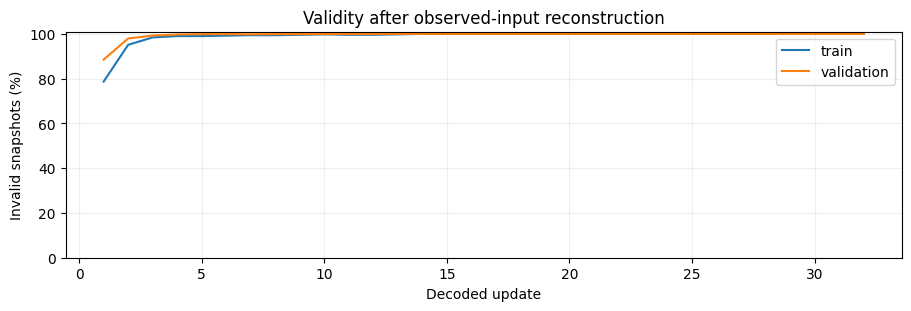

In [18]:
diagnostic = json.loads((project / "reports/timegan/diagnostics.json").read_text())
rows = []
for split, d in diagnostic["splits"].items():
    for name, key in [("Raw real books", "real"), ("Feature round trip", "roundtrip"), ("Encoder + recovery", "reconstruction"), ("Real returns, shifted anchors", "shuffled_anchor_mean")]:
        rows.append([split, name, d["windows"], *[100 * d[key][k] for k in ("invalid_rate", "ask_order_rate", "bid_order_rate", "crossed_rate")]])
display(pd.DataFrame(rows, columns=["Split", "Diagnostic", "Windows", "Invalid (%)", "Unordered asks (%)", "Unordered bids (%)", "Crossed L1 (%)"]).set_index(["Split", "Diagnostic"]).round(3))
rows = [[split, name, values["scaled_mse"], values["scaled_variance"], values["mse_over_variance"]]
        for split, d in diagnostic["splits"].items() for name, values in d["feature_groups"].items()]
display(pd.DataFrame(rows, columns=["Split", "Features", "Reconstruction MSE", "Within-split variance", "MSE / variance"]).set_index(["Split", "Features"]).round(6))
print("Variance is a descriptive constant-mean control computed within each diagnostic split, not a fitted forecasting baseline.")
fig, ax = plt.subplots(figsize=(9, 3), layout="constrained")
for split, d in diagnostic["splits"].items():
    ax.plot(np.arange(1, 33), 100 * np.array(d["reconstruction_invalid_by_update"]), label=split)
ax.set(xlabel="Decoded update", ylabel="Invalid snapshots (%)", title="Validity after observed-input reconstruction", ylim=(0, 101))
ax.legend(); ax.grid(alpha=.2); plt.show()

Price reconstruction and the return/anchor relationship both need attention. Small feature errors can accumulate into price-order violations.
The average reconstruction loss mixes price and volume features whose variances differ substantially. The table measures their errors separately;
it does not establish that changing loss weights will solve generation. A valid return path need not remain valid on an unrelated starting ladder.

### 8. Focused tuning

The first controlled experiments change learning rate (0.001 to 0.0003) or hidden width (24 to 48), retaining the reference GRU, losses,
three-stage schedule, batch size 128, training seed 2026 and 1,000 updates per stage. Additional budgets or training seeds are labelled below.
All candidates use identical chronological splits, anchors, metric settings and generation seeds. Checkpoint selection prioritises invalidity,
then mean KL, ACF error and earlier step. Configuration comparisons are exploratory validation results; test scoring remains deferred.
Runs can overlap on the CPU, so elapsed times are resource records rather than isolated speed benchmarks.

The separately labelled structural extension adds a mean hinge penalty over the nine ask gaps, nine bid gaps and best spread:

$$L_{order}=\frac{1}{19BT}\sum_{b,t,j}\max(0,1-g_{btj}/m).$$

Here $g$ is an adjacent ask difference, the reversed adjacent bid difference, or best ask minus best bid. Prices are decoded differentiably
from returns using training anchors; $m$ is the smallest positive training-book gap in USD. The weighted penalty is added to reconstruction
pretraining, joint encoder/recovery learning and generator learning. It changes the original objective, while preserving the five networks,
log-return features and noise-only inference. No validation anchors enter fitting and no inference repair is used. Validity is encouraged,
not guaranteed; lower invalidity must be assessed alongside return variation and distribution errors.


,Temporal supervision,Width,LR,Training seed,Order weight,Price weight,Stage updates,Selected step,Minutes
Run,,,,,,,,,
reference1000,Present,24,0.0010,2026,0.000,1.00000,1000/1000/1000,500,16.82405
lr0003,Present,24,0.0003,2026,0.000,1.00000,1000/1000/1000,1000,25.13909
order01,Present,24,0.0010,2026,0.100,1.00000,1000/1000/1000,750,24.86284
hidden48,Present,48,0.0010,2026,0.000,1.00000,1000/1000/1000,750,39.32925
order1,Present,24,0.0010,2026,1.000,1.00000,1000/1000/1000,1000,22.54851
night_reference_s2026,Present,24,0.0010,2026,0.000,1.00000,5000/5000/5000,5000,67.73189
night_gentle_s2026,Present,24,0.0010,2026,0.001,1.00000,5000/5000/5000,4000,68.91238
night_reference_s2027,Present,24,0.0010,2027,0.000,1.00000,5000/5000/5000,5000,64.21191
night_gentle_s2027,Present,24,0.0010,2027,0.001,1.00000,5000/5000/5000,5000,66.35341


,Invalid (%),Spread KL,Return KL,ACF error,Depth SSIM
Run,,,,,
reference1000,97.50772,0.31577,0.75878,0.07145,0.13054
lr0003,98.69309,0.09965,0.72780,0.09374,0.14832
order01,2.39583,0.12470,2.39755,0.16391,0.22275
hidden48,97.55594,0.09483,0.69249,0.02359,0.11276
order1,0.02315,1.34815,2.67825,0.12343,0.22698
night_reference_s2026,76.38696,0.07141,0.77720,0.05378,0.12401
night_gentle_s2026,38.28800,0.37595,0.74446,0.05491,0.11981
night_reference_s2027,64.90355,0.07316,0.85302,0.01763,0.10235
night_gentle_s2027,36.63870,0.26499,0.80944,0.23167,0.11886


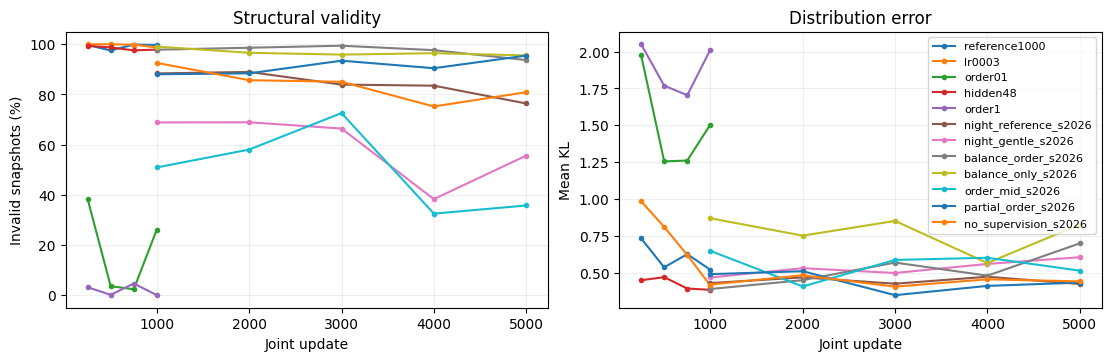

Generation-seed variation is not independent retraining uncertainty. See training-seed labels before comparing runs. Trajectories show seed 2026 for overnight runs; the table retains all seeds.
Selected reference: night_reference_s2026
Selected extension: night_gentle_s2026


Metric,ACF error,Depth SSIM,Invalid (%),Return KL,Spread KL
Model,,,,,
Gentle order penalty,0.1023 +/- 0.1134,0.1229 +/- 0.0062,39.3991 +/- 3.4528,0.7444 +/- 0.0650,0.2662 +/- 0.1091
Moderate order penalty,0.3010 +/- 0.2299,0.1274 +/- 0.0021,37.5698 +/- 4.6582,0.9100 +/- 0.0555,0.2334 +/- 0.0172
Reference,0.1254 +/- 0.1564,0.1157 +/- 0.0116,72.0570 +/- 6.2407,0.7746 +/- 0.0798,0.0745 +/- 0.0040


Three independent fits per group; generation seeds are averaged within each fit. SD is not a confidence interval.


Metric                                        ACF error         Depth SSIM  \
Model                  Training_seed                                         
Gentle order penalty   2026           0.0549 +/- 0.0019  0.1198 +/- 0.0040   
                       2027           0.2317 +/- 0.0076  0.1189 +/- 0.0041   
                       2028           0.0203 +/- 0.0015  0.1300 +/- 0.0056   
Moderate order penalty 2026           0.4669 +/- 0.0083  0.1256 +/- 0.0034   
                       2027           0.3976 +/- 0.0085  0.1270 +/- 0.0002   
                       2028           0.0386 +/- 0.0023  0.1297 +/- 0.0048   
Reference              2026           0.0538 +/- 0.0041  0.1240 +/- 0.0015   
                       2027           0.0176 +/- 0.0008  0.1024 +/- 0.0017   
                       2028           0.3049 +/- 0.0036  0.1206 +/- 0.0018   

Metric                                       Invalid (%)          Return KL  \
Model                  Training_seed                                          
Gentle order penalty   2026           38.2880 +/- 0.6400  0.7445 +/- 0.0032   
                       2027           36.6387 +/- 1.7544  0.8094 +/- 0.0238   
                       2028           43.2706 +/- 0.9924  0.6794 +/- 0.0029   
Moderate order penalty 2026           32.5019 +/- 0.9295  0.9712 +/- 0.0178   
                       2027           41.6647 +/- 0.9903  0.8628 +/- 0.0235   
                       2028           38.5426 +/- 1.8420  0.8959 +/- 0.0047   
Reference              2026           76.3870 +/- 0.4467  0.7772 +/- 0.0047   
                       2027           64.9035 +/- 0.6751  0.8530 +/- 0.0057   
                       2028           74.8804 +/- 0.8140  0.6935 +/- 0.0169   

Metric                                        Spread KL  
Model                  Training_seed                     
Gentle order penalty   2026           0.3759 +/- 0.0021  
                       2027           0.2650 +/- 0.0064  
                       2028           0.1577 +/- 0.0086  
Moderate order penalty 2026           0.2328 +/- 0.0090  
                       2027           0.2165 +/- 0.0114  
                       2028           0.2510 +/- 0.0081  
Reference              2026           0.0714 +/- 0.0068  
                       2027           0.0732 +/- 0.0019  
                       2028           0.0790 +/- 0.0089

Within-fit variation across generation seeds 42/43/44 is separate from the retraining SD above.


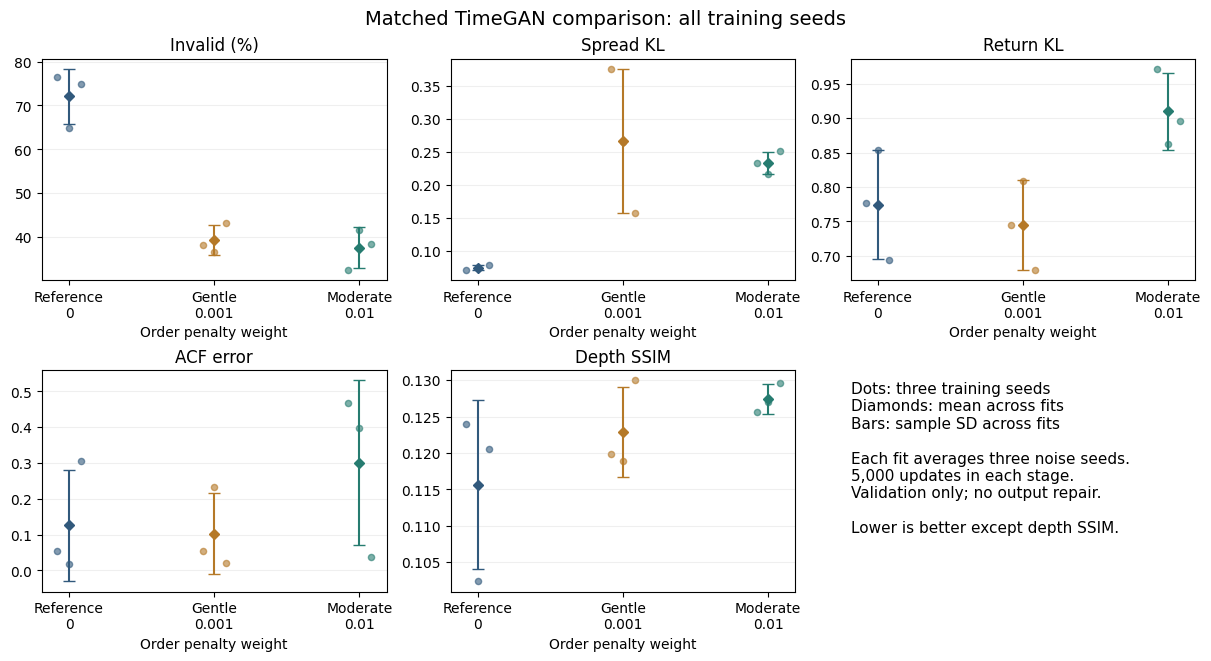

In [19]:
tuning = json.loads((project / "reports/timegan/tuning.json").read_text())
candidates = tuning["candidates"]
rows = []
for name, run in candidates.items():
    assert run["comparison_signature"] == report["comparison_signature"]
    cfg, score = run["config"], run["selected"]
    budget = f"{cfg['embedding_steps']}/{cfg.get('effective_supervised_steps', cfg['supervised_steps'])}/{cfg['joint_steps']}"
    rows.append([name, "Removed" if cfg.get("no_supervision", False) else "Present", cfg["architecture"]["hidden"], cfg["learning_rate"], cfg["training_seed"], cfg.get("structure_weight", 0.), cfg.get("price_reconstruction_weight", 1.), budget, score["step"],
                 *[score[key + "_mean"] * scale for key, _, scale in metrics], run["total_seconds"] / 60])
columns = ["Run", "Temporal supervision", "Width", "LR", "Training seed", "Order weight", "Price weight", "Stage updates", "Selected step", *[label for _, label, _ in metrics], "Minutes"]
experiment_table = pd.DataFrame(rows, columns=columns).set_index("Run")
display(experiment_table[["Temporal supervision", "Width", "LR", "Training seed", "Order weight", "Price weight", "Stage updates", "Selected step", "Minutes"]].round(5))
display(experiment_table[[label for _, label, _ in metrics]].round(5))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
for name, run in candidates.items():
    if run["config"]["training_seed"] != 2026: continue
    trajectory = pd.DataFrame(run["validation_history"])
    axes[0].plot(trajectory.step, trajectory.invalid_rate_mean * 100, marker=".", label=name)
    axes[1].plot(trajectory.step, trajectory.mean_kl_mean, marker=".", label=name)
axes[0].set(ylabel="Invalid snapshots (%)", xlabel="Joint update", title="Structural validity")
axes[1].set(ylabel="Mean KL", xlabel="Joint update", title="Distribution error")
for ax in axes: ax.grid(alpha=.2)
axes[1].legend(fontsize=8); plt.show()
print("Generation-seed variation is not independent retraining uncertainty. See training-seed labels before comparing runs. Trajectories show seed 2026 for overnight runs; the table retains all seeds.")
for label in ("selected_reference", "selected_extension"):
    if label in tuning:
        print(label.replace("_", " ").capitalize() + ":", tuning[label])
if "training_seed_summary" in tuning:
    seed_table = pd.DataFrame(tuning["training_seed_summary"])
    scales = {key: scale for key, _, scale in metrics}
    labels = {key: label for key, label, _ in metrics}
    seed_table["Mean +/- training SD"] = seed_table.apply(lambda r: f"{r.Mean * scales[r.Metric]:.4f} +/- {r.SD * scales[r.Metric]:.4f}", axis=1)
    display(seed_table.pivot(index="Model", columns="Metric", values="Mean +/- training SD").rename(columns=labels))
    print("Three independent fits per group; generation seeds are averaged within each fit. SD is not a confidence interval.")

noise_table = pd.DataFrame(tuning.get("generation_seed_summary", []))
if not noise_table.empty:
    noise_table["Mean +/- generation SD"] = noise_table.apply(lambda r: f"{r.Generation_mean * scales[r.Metric]:.4f} +/- {r.Generation_SD * scales[r.Metric]:.4f}", axis=1)
    display(noise_table.pivot(index=["Model", "Training_seed"], columns="Metric", values="Mean +/- generation SD").rename(columns=labels))
    print("Within-fit variation across generation seeds 42/43/44 is separate from the retraining SD above.")

fig, axes = plt.subplots(2, 3, figsize=(12, 6.5), layout="constrained")
group_names = ["Reference", "Gentle order penalty", "Moderate order penalty"]
tick_labels = ["Reference\n0", "Gentle\n0.001", "Moderate\n0.01"]
colours = ["#31597c", "#b57928", "#267c70"]
for ax, (key, label, scale) in zip(axes.flat, metrics):
    for x, (group, colour) in enumerate(zip(group_names, colours)):
        row = seed_table[(seed_table.Model == group) & (seed_table.Metric == key)].iloc[0]
        values = noise_table[(noise_table.Model == group) & (noise_table.Metric == key)].sort_values("Training_seed").Generation_mean.to_numpy() * scale
        ax.scatter(x + np.linspace(-.08, .08, len(values)), values, color=colour, s=20, alpha=.6)
        ax.errorbar(x, row.Mean * scale, yerr=row.SD * scale, fmt="D", color=colour, capsize=4, markersize=5)
    ax.set(xticks=range(3), xticklabels=tick_labels, title=label, xlabel="Order penalty weight")
    ax.grid(axis="y", alpha=.2)
axes.flat[-1].axis("off")
axes.flat[-1].text(0, .95, "Dots: three training seeds\nDiamonds: mean across fits\nBars: sample SD across fits\n\nEach fit averages three noise seeds.\n5,000 updates in each stage.\nValidation only; no output repair.\n\nLower is better except depth SSIM.", va="top", fontsize=11)
fig.suptitle("Matched TimeGAN comparison: all training seeds", fontsize=14)
plt.show()


### Overnight paired comparison

The 1,000-per-stage penalty pilots reduced invalidity, but between-sequence feature SD fell to $8.9\times10^{-5}$ at weight 0.1
and $3.9\times10^{-7}$ at weight 1. This is near-collapse, not successful simulation. A separately planned longer experiment compares the tuned reference objective
with a 100-times-smaller penalty of 0.001. Both use the same width, learning rate, stage budgets and training seeds 2026/2027/2028.
The budget is chosen once from measured pilot timings (2,000, 3,000 or 5,000 updates per stage), then frozen across all six runs.
The original checkpoint-selection rule is unchanged, so a structurally better checkpoint can still be unsuitable because of collapsed diversity.
All such results stay visible. Seed 2026 is fixed in advance for examples; it is not chosen for its score.

The summary SD measures variation across independent fits, after averaging the three generation seeds within each fit. All scores remain
validation estimates after tuning and checkpoint selection. No final test scores are produced by this overnight job.

Reference pilot: reference1000 | width: 24 | LR: 0.001
Updates per stage: 5000 | training seeds: 2026, 2027, 2028 | penalty weights: 0 and 0.001
All six retraining runs complete: True


,Between-sequence feature SD,Price SD / real,Volume SD / real
Run,,,
reference1000,5.044590e-02,1.585313,0.704204
lr0003,4.492210e-02,1.629869,0.621183
order01,8.880000e-05,1.196862,0.029200
hidden48,6.448220e-02,1.769022,0.897820
order1,4.000000e-07,2.063027,0.020784
night_reference_s2026,6.419680e-02,1.095167,0.913543
night_gentle_s2026,6.167740e-02,1.052137,0.879348
night_reference_s2027,6.626120e-02,1.600850,0.924925
night_gentle_s2027,6.640780e-02,1.569580,0.932553


Pooled feature SD also includes variation over time; it cannot alone rule out noise-to-noise collapse.


,Generation seed,Between-sequence price SD,Between-sequence volume SD
Run,,,
night_reference_s2026,42,0.004891,0.123503
night_gentle_s2026,42,0.004623,0.118732
night_reference_s2027,42,0.007176,0.125346
night_gentle_s2027,42,0.006976,0.125839
night_reference_s2028,42,0.004912,0.118773
night_gentle_s2028,42,0.005286,0.118864
balance_only_s2026,42,0.008366,0.096914
balance_order_s2026,42,0.009204,0.110916
partial_order_s2026,42,0.009609,0.106537


Separate feature groups check sensitivity to noise at fixed update positions; these diagnostics use generation seed 42.


,Reconstructed invalid (%),Price MSE / variance,Volume MSE / variance
Run,,,
night_reference_s2026,74.85243,1.03934,0.23175
night_gentle_s2026,25.76678,1.16159,0.25240
night_reference_s2027,71.75926,1.00549,0.16903
night_gentle_s2027,30.48611,1.12410,0.25480
night_reference_s2028,68.81076,1.03050,0.22829
night_gentle_s2028,23.52720,1.05020,0.24347
balance_only_s2026,82.69387,0.40063,0.63634
balance_order_s2026,85.54109,0.44053,0.60078
partial_order_s2026,61.76215,0.75609,0.45615


night_reference_s2026: examples

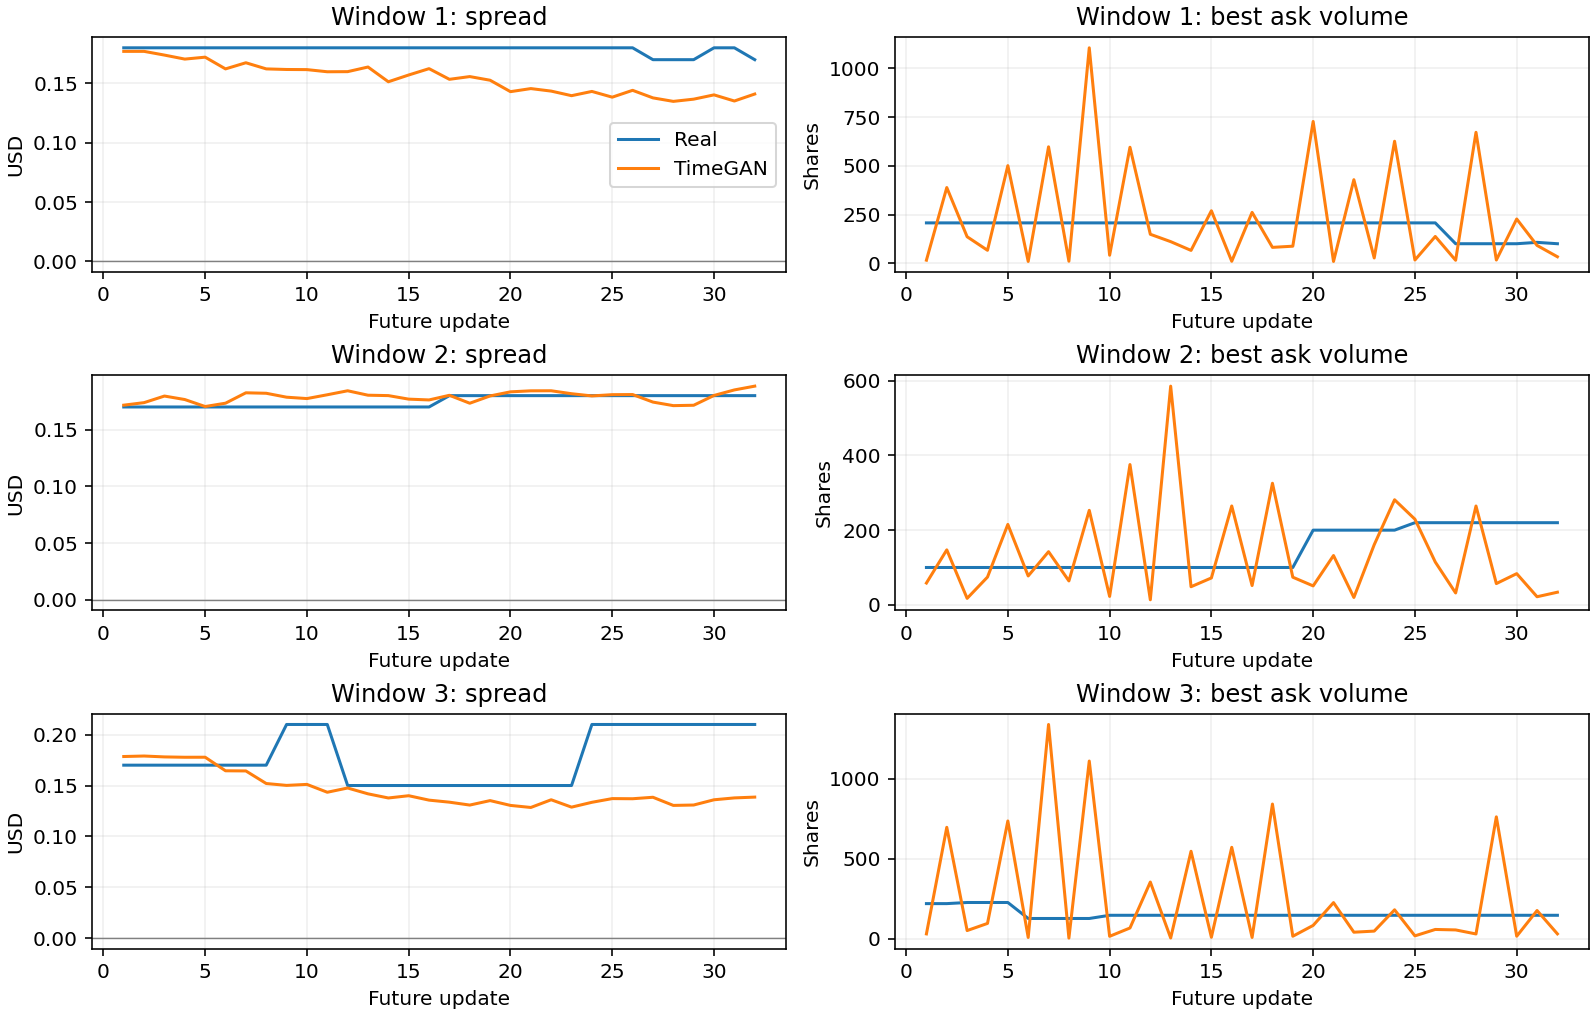

night_reference_s2026: depth

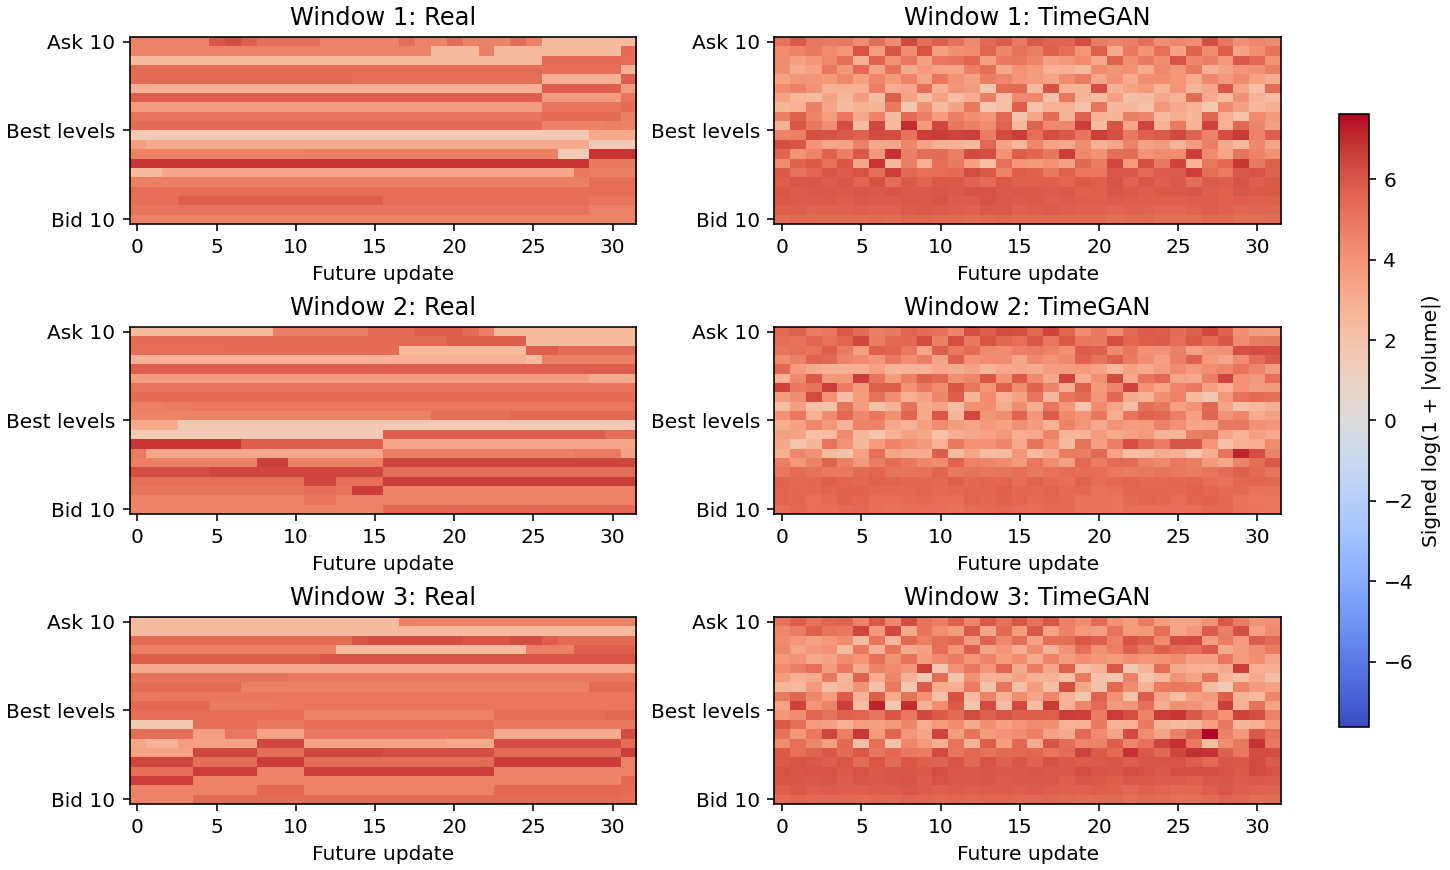

night_gentle_s2026: examples

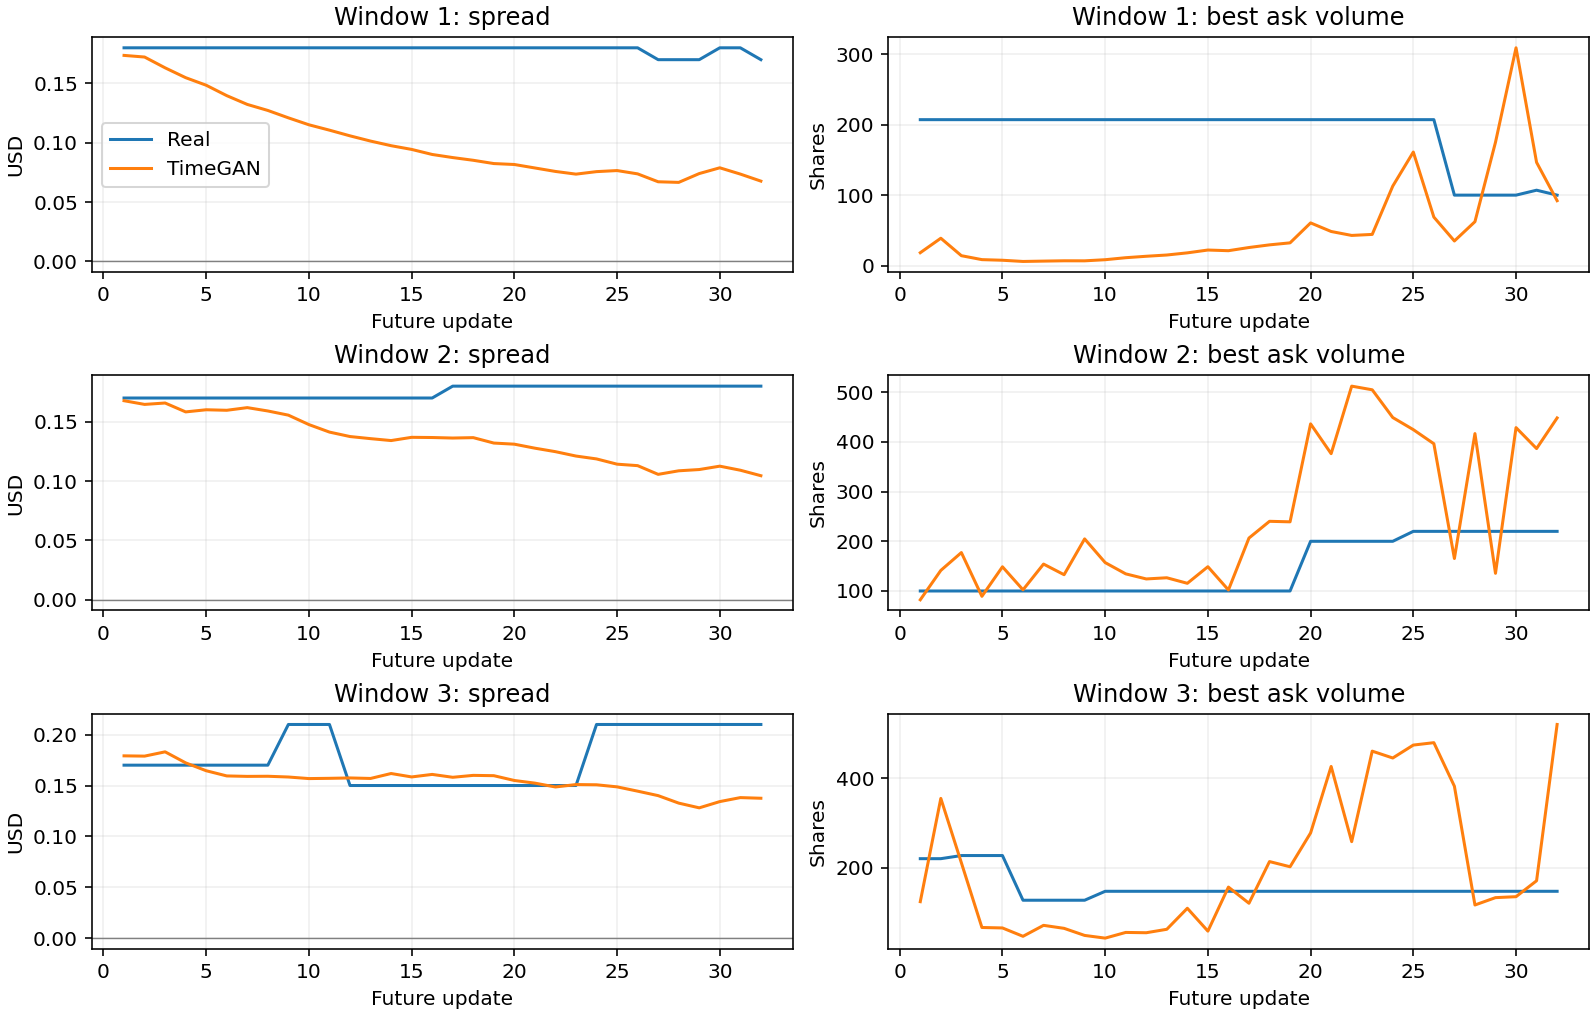

night_gentle_s2026: depth

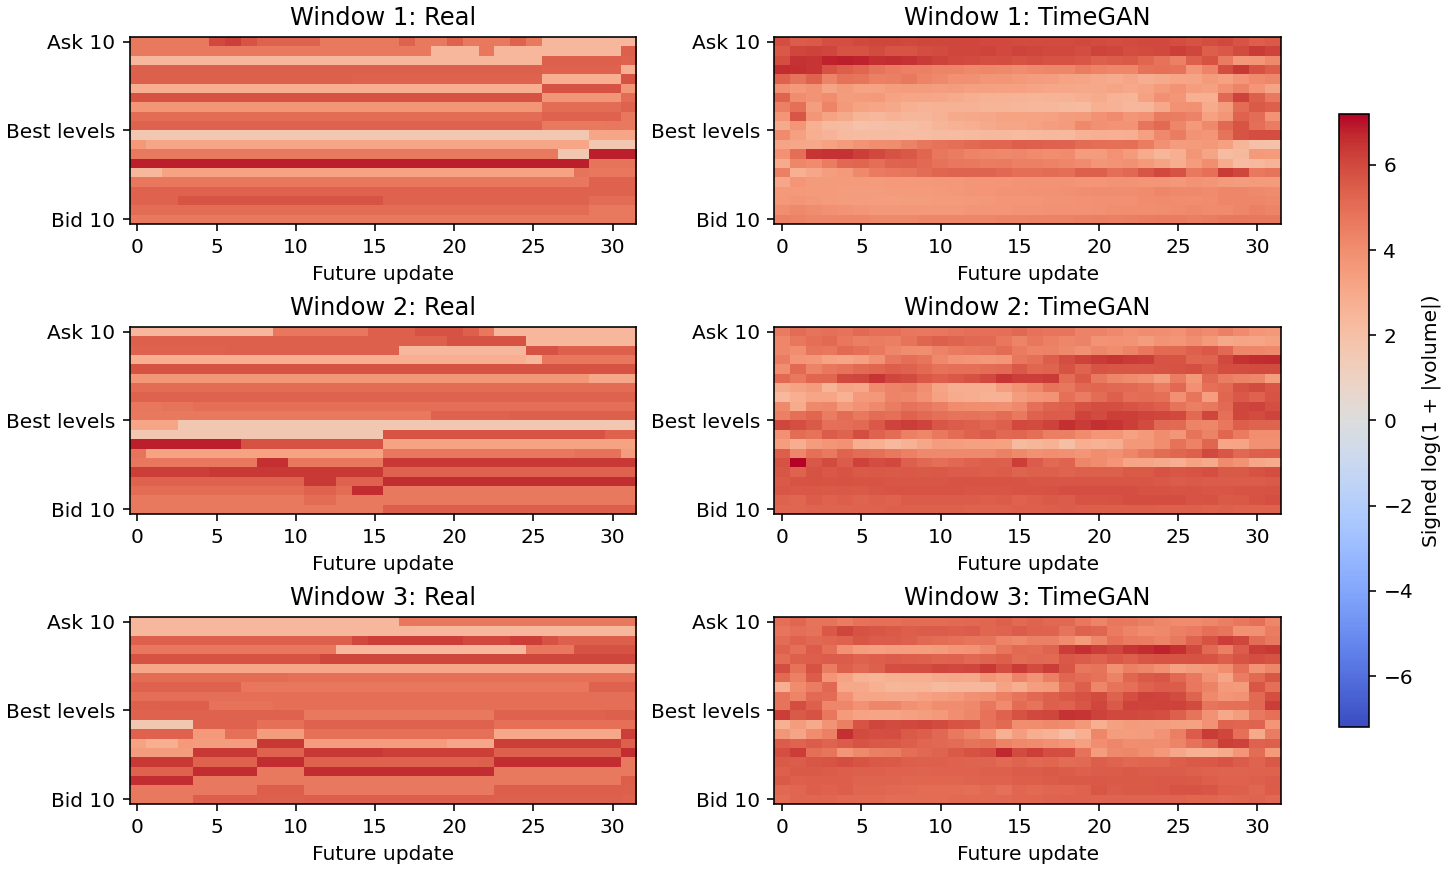

order_mid_s2026: examples

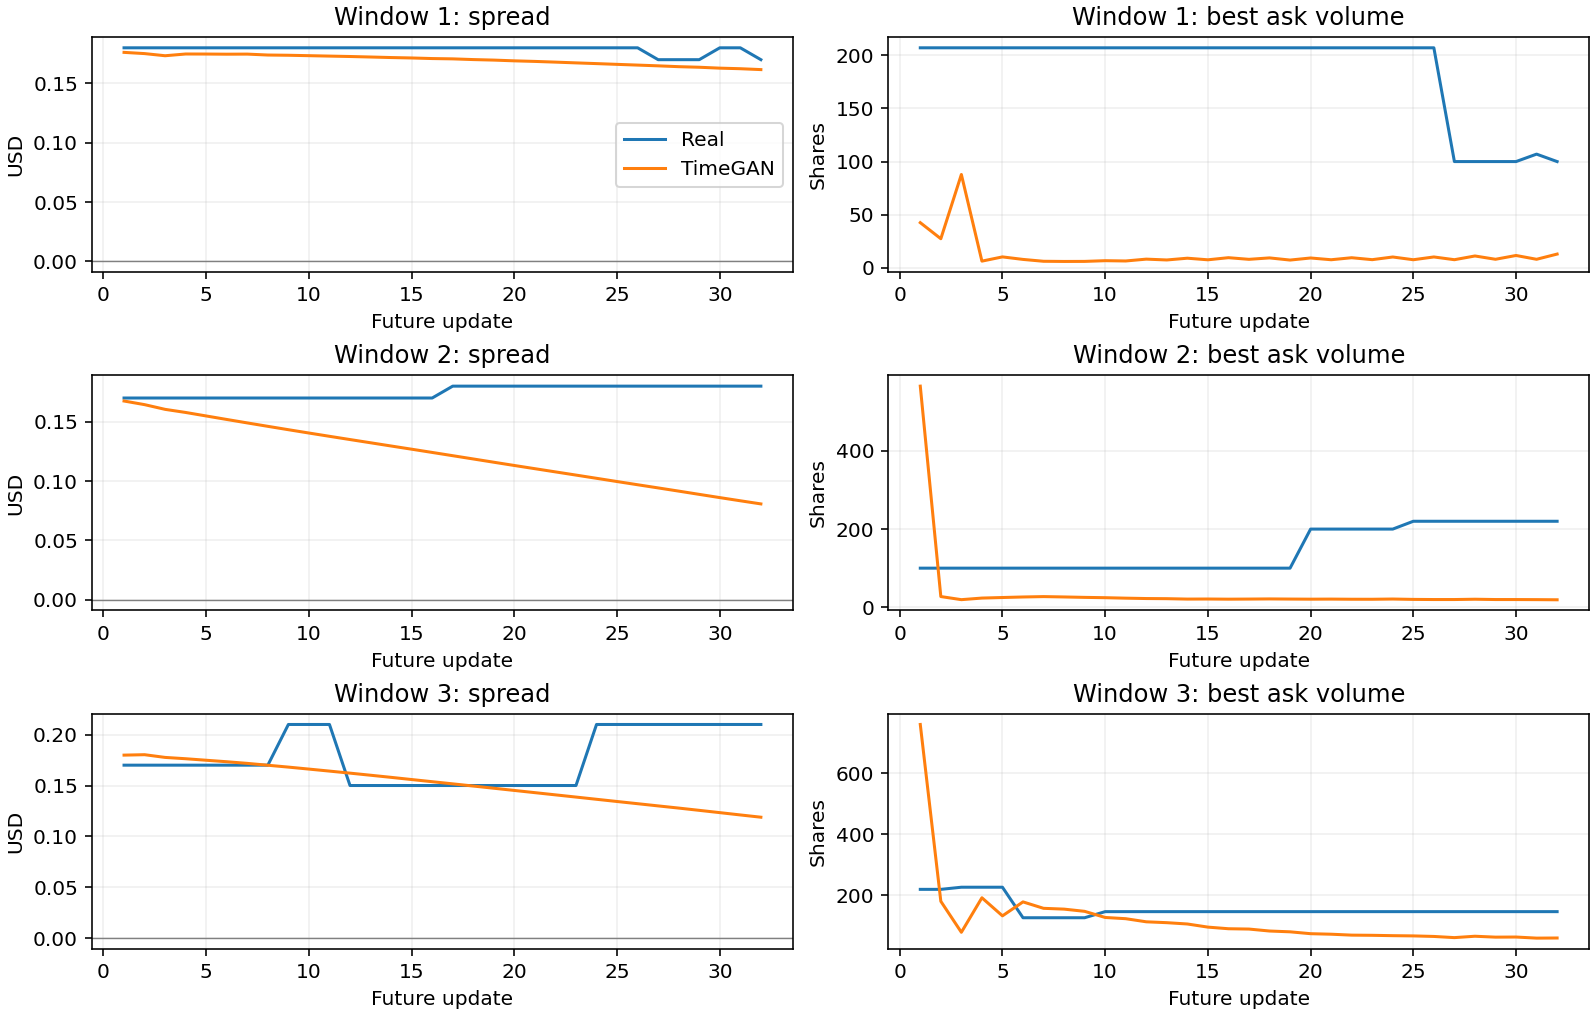

order_mid_s2026: depth

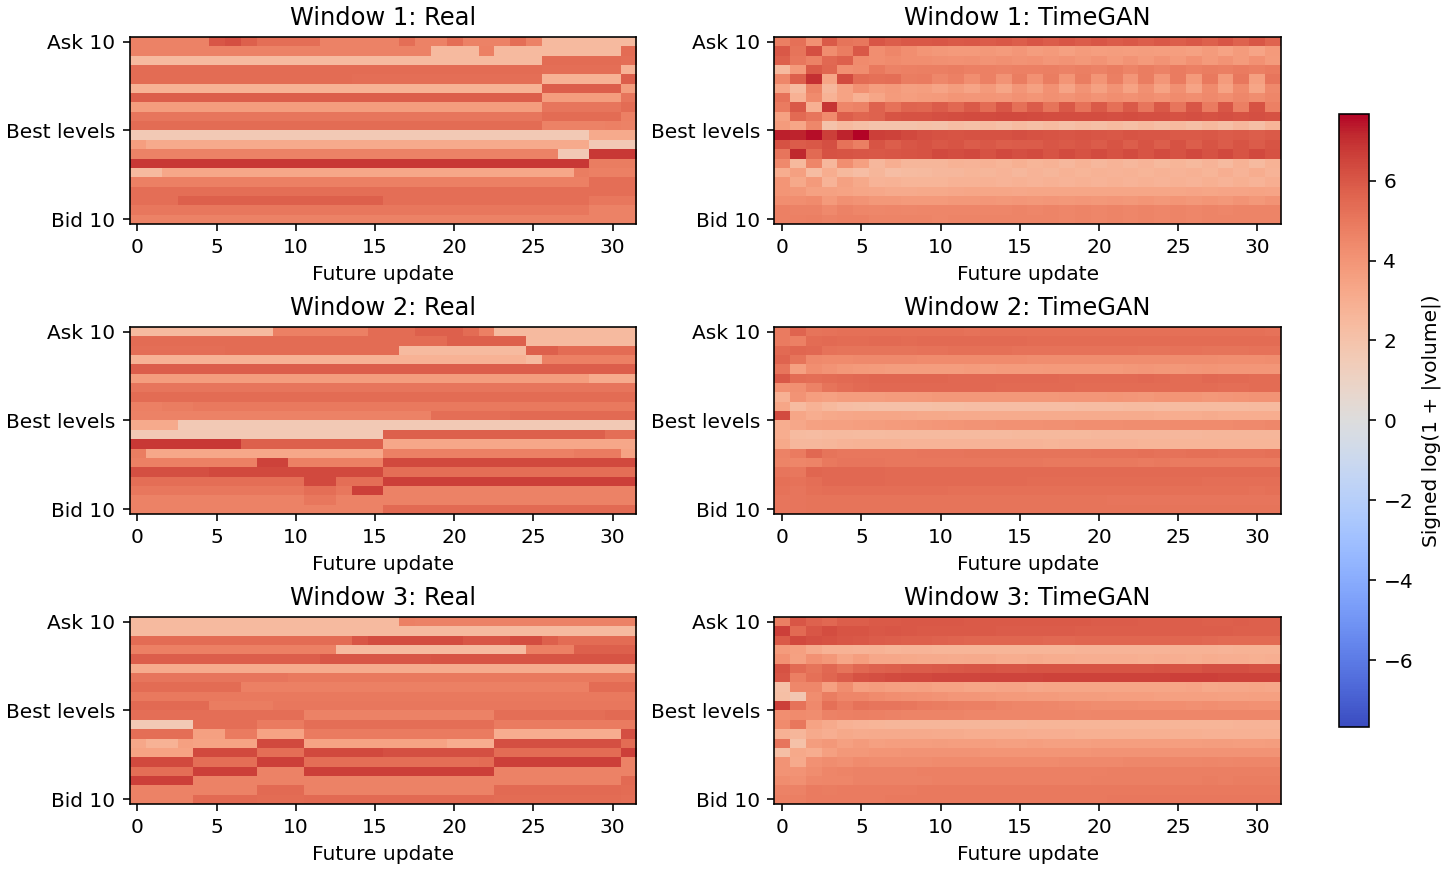

In [20]:
if "overnight_plan" in tuning:
    plan = tuning["overnight_plan"]
    print("Reference pilot:", plan["reference_pilot"], "| width:", plan["hidden"], "| LR:", plan["learning_rate"])
    print("Updates per stage:", plan["steps_per_stage"], "| training seeds: 2026, 2027, 2028 | penalty weights: 0 and 0.001")
    print("All six retraining runs complete:", tuning.get("complete_training_seed_comparison", False))
else:
    print("Overnight settings will be frozen after the pilot runs complete.")
variation = []
for name, run in candidates.items():
    d = run["selected"]["diversity"]
    real_sd, gen_sd = np.asarray(d["real_feature_std"]), np.asarray(d["generated_feature_std"])
    variation.append([name, d["mean_between_sequence_std"], gen_sd[::2].mean() / real_sd[::2].mean(), gen_sd[1::2].mean() / real_sd[1::2].mean()])
display(pd.DataFrame(variation, columns=["Run", "Between-sequence feature SD", "Price SD / real", "Volume SD / real"]).set_index("Run").round(7))
print("Pooled feature SD also includes variation over time; it cannot alone rule out noise-to-noise collapse.")
noise_checks = tuning.get("noise_diversity_diagnostics", {})
if noise_checks:
    for name, d in noise_checks.items():
        assert d["checkpoint_sha256"] == candidates[name]["selected_checkpoint_sha256"]
    rows = [[name, d["generation_seed"], d["price_between_sequence_sd"], d["volume_between_sequence_sd"]] for name, d in noise_checks.items()]
    display(pd.DataFrame(rows, columns=["Run", "Generation seed", "Between-sequence price SD", "Between-sequence volume SD"]).set_index("Run").round(7))
    print("Separate feature groups check sensitivity to noise at fixed update positions; these diagnostics use generation seed 42.")
checks = tuning.get("followup_diagnostics", {})
if checks:
    rows = [[name, d["splits"]["validation"]["reconstruction"]["invalid_rate"] * 100,
             d["splits"]["validation"]["feature_groups"]["price"]["mse_over_variance"],
             d["splits"]["validation"]["feature_groups"]["volume"]["mse_over_variance"]] for name,d in checks.items()]
    display(pd.DataFrame(rows, columns=["Run", "Reconstructed invalid (%)", "Price MSE / variance", "Volume MSE / variance"]).set_index("Run").round(5))
for fig in tuning.get("overnight_figures", []):
    image_path = project / "reports/timegan" / fig["file"]
    assert hashlib.sha256(image_path.read_bytes()).hexdigest() == fig["sha256"]
    display(Markdown(fig["run"] + ": " + fig["role"]))
    display(Image(filename=str(image_path), width=1000))

### Reconstruction balance follow-up

Across three training seeds, the 5,000-per-stage reference averaged 72.06% invalid snapshots; the gentle penalty averaged 39.40%.
Their SDs are 6.24 and 3.45 percentage points. Return KL and depth SSIM remain poor, and temporal error varies between fits.

The reconstruction extension weights price errors using the training-window volume/price variance ratio $r$:

$$L_{\mathrm{rec},w}=\operatorname{mean}_{b,t,j}\left[w_j(\hat{x}_{btj}-x_{btj})^2\right],\qquad
w_{\mathrm{price}}=r^a,\quad w_{\mathrm{volume}}=1,\quad r=115.0596.$$

It replaces reconstruction MSE under the original $10\sqrt{L_{\mathrm{rec}}}$ term during embedding pretraining and joint learning.
The generator's adversarial, moment and temporal terms are unchanged; the order penalty is specified separately. This is an extension.

Full weighting ($a=1$) failed: invalidity was 95.54% without the order loss and 93.69% with weight 0.001. Price reconstruction MSE/variance
improved to 0.401/0.441, but volume error worsened to 0.636/0.601. Lower per-feature error did not preserve the price ladder. All failures remain visible.

Partial weighting ($a=0.5$, price weight 10.7266) with order weight 0.001 also failed: 88.03% invalid snapshots.
Price reconstruction MSE/variance was 0.756 and volume error 0.456. Return KL improved to 0.542, but ladder violations remained severe.

The moderate order penalty (0.01, unweighted reconstruction) reached 32.50% invalidity versus 38.29% for the matched gentle run.
Spread KL improved from 0.376 to 0.233, while return KL worsened from 0.744 to 0.971 and ACF error from 0.055 to 0.467.
Depth SSIM changed from 0.120 to 0.126. Separate noise-to-noise price/volume SD was 0.00326/0.11289, so this was not near-identical output collapse.
It is a validity/fidelity trade-off, not an overall successful simulator. Fixed examples show smoothly drifting spreads and strong initial volume transients rather than the observed stepwise updates.

These comparisons use training seed 2026, width 24, learning rate 0.001, 5,000 updates per stage and unchanged generation seeds/anchors.
Each new setting changes one factor against the earlier gentle run. The older 0.1 collapse pilot has a shorter budget and is contextual evidence only.
The repeats are complete: invalidity was 41.66% at seed 2027 and 38.54% at seed 2028. Across all three fits the moderate penalty averaged
37.57% +/- 4.66 percentage points invalidity, return KL 0.910 +/- 0.056, ACF error 0.301 +/- 0.230 and depth SSIM 0.127 +/- 0.002.
The modest average validity gain over the gentle penalty did not hold at every seed, and return KL/ACF error worsened at all three.
Price noise SD ranged from 0.00134 to 0.00518; volume noise SD ranged from 0.11289 to 0.11811. Neither uniqueness nor nonzero variation proves realistic returns.


### 9. Reference-run interpretation

The historical table below compares the 1,000-per-stage reference run with the earlier implementation check. Both use the same source, seed and settings apart from
training budgets and validation checkpoint frequency. The original GPU pilot also changed cell equations, initialisation and architecture,
so differences against that run cannot isolate a single implementation change. Neither generation-seed SD nor exact uniqueness proves
reliable training or rules out collapse.

Use structural violations, distribution errors and diversity together when assessing the simulator. The paired reference, gentle and moderate groups above measure retraining variation; reconstruction-weighted variants remain single-seed experiments. The temporal-supervision ablation is reported in Section 2 above. Keep test scoring until the configuration is fixed.

Section 2.7 asks whether TimeGAN learns order-book constraints and specifies price log returns. Keep this as the main investigation.
A decoder that enforces positive spreads/gaps would be a separately labelled engineering extension: its validity would come from the
representation. Clarify with the tutor before replacing the specified main representation. One stock/day limits broader conclusions.

In [21]:
ar_selected = next(row for row in report["ar_baselines"] if row["candidate"] == report["ar_selected_candidate"])
better, worse = [], []
for key, label, _ in metrics:
    improvement = selected[key + "_mean"] > ar_selected[key + "_mean"] if key == "depth_ssim" else selected[key + "_mean"] < ar_selected[key + "_mean"]
    (better if improvement else worse).append(label)
display(Markdown(f"On this validation run, TimeGAN has better {', '.join(better) or 'none of these measures'}; it has no improvement in {', '.join(worse) or 'any remaining measure'}. "
                 f"Invalid snapshots are {selected['invalid_rate_mean']:.2%}, compared with {ar_selected['invalid_rate_mean']:.2%} for AR. "
                 f"{sum(passed for _, passed in criteria)} of {len(criteria)} measured simulator targets are met."))
sample_rows = pd.DataFrame(report["example_diagnostics"])
sample_rows = sample_rows[sample_rows.model == "TimeGAN"]
for row in sample_rows.itertuples():
    print(f"Window {row.window}: {row.invalid_rate:.1%} invalid, {row.crossed_rate:.1%} with nonpositive best spread; depth SSIM {row.depth_ssim:.3f}.")

earlier = report["previous_runs"][-1]["selected"]
delta = [(label, earlier[key + "_mean"] * scale, selected[key + "_mean"] * scale,
          (selected[key + "_mean"] - earlier[key + "_mean"]) * scale) for key, label, scale in metrics]
display(pd.DataFrame(delta, columns=["Measure", "Reference check", "Longer reference run", "Change"]).set_index("Measure").round(5))
print("These differences concern selected validation checkpoints from one training seed; they do not measure retraining uncertainty.")

display(Markdown(f"At the selected checkpoint, nonpositive best spreads occur in {selected['crossed_rate_mean']:.2%} of generated snapshots, "
                 f"but unordered ask/bid ladders occur in {selected['ask_order_rate_mean']:.2%} / {selected['bid_order_rate_mean']:.2%}. "
                 "A valid best spread does not establish correct ordering at deeper levels. Violation rates overlap and should not be added."))
print(f"Mean between-sequence feature SD: {earlier['diversity']['mean_between_sequence_std']:.6f} in the short check -> "
      f"{selected['diversity']['mean_between_sequence_std']:.6f} in this run. Greater variation does not prove full distribution coverage.")


On this validation run, TimeGAN has better none of these measures; it has no improvement in Invalid (%), Spread KL, Return KL, ACF error, Depth SSIM. Invalid snapshots are 97.51%, compared with 93.02% for AR. 0 of 4 measured simulator targets are met.

Window 1: 100.0% invalid, 0.0% with nonpositive best spread; depth SSIM 0.010.
Window 2: 96.9% invalid, 0.0% with nonpositive best spread; depth SSIM -0.034.
Window 3: 96.9% invalid, 0.0% with nonpositive best spread; depth SSIM 0.082.


,Reference check,Longer reference run,Change
Measure,,,
Invalid (%),100.00000,97.50772,-2.49228
Spread KL,0.93557,0.31577,-0.61979
Return KL,0.24506,0.75878,0.51372
ACF error,0.44301,0.07145,-0.37156
Depth SSIM,0.22896,0.13054,-0.09842


These differences concern selected validation checkpoints from one training seed; they do not measure retraining uncertainty.


At the selected checkpoint, nonpositive best spreads occur in 0.00% of generated snapshots, but unordered ask/bid ladders occur in 95.39% / 96.19%. A valid best spread does not establish correct ordering at deeper levels. Violation rates overlap and should not be added.

Mean between-sequence feature SD: 0.001816 in the short check -> 0.050446 in this run. Greater variation does not prove full distribution coverage.


In [22]:
print("Comparison signature:", report["comparison_signature"])
print("Selected checkpoint SHA256:", report["selected_checkpoint_sha256"])
print(f"PyTorch {report['torch_version']}; NumPy {report['numpy_version']}; test evaluated: {report['test_evaluated']}.")
display(pd.DataFrame(report["input_files"])[["name", "sha256"]])

Comparison signature: e52140139de3081e194ba3224d3578d13f70173f3d8eae0bd81641cbeac3e6a5
Selected checkpoint SHA256: 6836e7b1d8fc247c2e8ae263ca43bb67653b8cc215a4498c01055c8eb35382ba
PyTorch 2.8.0+cu128; NumPy 2.2.6; test evaluated: False.


,name,sha256
0,AMZN_2012-06-21_34200000_57600000_message_10.csv,c85a75b51f3616a683f825c2e03f984535e9329a8be5ab...
1,AMZN_2012-06-21_34200000_57600000_orderbook_10...,decfe952b3fa06c9922dc8fba763a37a0fb032d4231767...
